In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
# !mkdir -p "/content/drive/MyDrive/MIMIC IV/hosp"
# !mkdir -p "/content/drive/MyDrive/MIMIC IV/icu"

# !wget -c --user amar007 --ask-password \
#   -P "/content/drive/MyDrive/MIMIC IV/hosp" \
#   https://physionet.org/files/mimiciv/3.1/hosp/patients.csv.gz \
#   https://physionet.org/files/mimiciv/3.1/hosp/admissions.csv.gz \
#   https://physionet.org/files/mimiciv/3.1/hosp/diagnoses_icd.csv.gz \
#   https://physionet.org/files/mimiciv/3.1/hosp/d_icd_diagnoses.csv.gz \
#   https://physionet.org/files/mimiciv/3.1/hosp/d_labitems.csv.gz \
#   https://physionet.org/files/mimiciv/3.1/hosp/omr.csv.gz \
#   https://physionet.org/files/mimiciv/3.1/hosp/labevents.csv.gz \


In [4]:
# !wget -c --user amar007 --ask-password \
#   -P "/content/drive/MyDrive/MIMIC IV/icu" \
#   https://physionet.org/files/mimiciv/3.1/icu/d_items.csv.gz \
#   https://physionet.org/files/mimiciv/3.1/icu/chartevents.csv.gz \

In [5]:
import os
import pandas as pd
import numpy as np

BASE_DIR = "/content/drive/MyDrive/MIMIC IV"

HOSP_DIR = os.path.join(BASE_DIR, "hosp")
ICU_DIR = os.path.join(BASE_DIR, "icu")

print("HOSP:", HOSP_DIR)
print("ICU :", ICU_DIR)

HOSP: /content/drive/MyDrive/MIMIC IV/hosp
ICU : /content/drive/MyDrive/MIMIC IV/icu


In [6]:
expected_files = {
    "hosp": [
        "patients.csv.gz",
        "admissions.csv.gz",
        "diagnoses_icd.csv.gz",
        "d_icd_diagnoses.csv.gz",
        "d_labitems.csv.gz",
        "omr.csv.gz",
        "labevents.csv.gz",
    ],
    "icu": [
        "chartevents.csv.gz",
        "d_items.csv.gz",
    ]
}

for folder, files in expected_files.items():
    folder_path = os.path.join(BASE_DIR, folder)

    print(f"\n{folder.upper()}")
    print("-" * 50)

    for file in files:
        path = os.path.join(folder_path, file)
        print("✓" if os.path.exists(path) else "✗", file)


HOSP
--------------------------------------------------
✓ patients.csv.gz
✓ admissions.csv.gz
✓ diagnoses_icd.csv.gz
✓ d_icd_diagnoses.csv.gz
✓ d_labitems.csv.gz
✓ omr.csv.gz
✓ labevents.csv.gz

ICU
--------------------------------------------------
✗ chartevents.csv.gz
✓ d_items.csv.gz


In [7]:
patients_path = os.path.join(HOSP_DIR, "patients.csv.gz")
admissions_path = os.path.join(HOSP_DIR, "admissions.csv.gz")
diagnoses_path = os.path.join(HOSP_DIR, "diagnoses_icd.csv.gz")
d_icd_path = os.path.join(HOSP_DIR, "d_icd_diagnoses.csv.gz")
d_labitems_path = os.path.join(HOSP_DIR, "d_labitems.csv.gz")
omr_path = os.path.join(HOSP_DIR, "omr.csv.gz")
d_items_path = os.path.join(ICU_DIR, "d_items.csv.gz")
labevents_path = os.path.join(ICU_DIR, "labevents.csv.gz")
chartevents_path = os.path.join(ICU_DIR, "chartevents.csv.gz")


In [8]:
patients = pd.read_csv(patients_path)
print(patients.shape)
print(patients.columns.tolist())
patients.head()

admissions = pd.read_csv(admissions_path)
print(admissions.shape)
print(admissions.columns.tolist())
admissions.head()

diagnoses = pd.read_csv(diagnoses_path)
print(diagnoses.shape)
print(diagnoses.columns.tolist())
diagnoses.head()

d_icd = pd.read_csv(d_icd_path)
print(d_icd.shape)
print(d_icd.columns.tolist())
d_icd.head()

d_labitems = pd.read_csv(d_labitems_path)
print(d_labitems.shape)
print(d_labitems.columns.tolist())
d_labitems.head()

omr = pd.read_csv(omr_path)
print(omr.shape)
print(omr.columns.tolist())
omr.head()

d_items = pd.read_csv(d_items_path)
print(d_items.shape)
print(d_items.columns.tolist())
d_items.head()

(364627, 6)
['subject_id', 'gender', 'anchor_age', 'anchor_year', 'anchor_year_group', 'dod']
(546028, 16)
['subject_id', 'hadm_id', 'admittime', 'dischtime', 'deathtime', 'admission_type', 'admit_provider_id', 'admission_location', 'discharge_location', 'insurance', 'language', 'marital_status', 'race', 'edregtime', 'edouttime', 'hospital_expire_flag']
(6364488, 5)
['subject_id', 'hadm_id', 'seq_num', 'icd_code', 'icd_version']
(112107, 3)
['icd_code', 'icd_version', 'long_title']
(1650, 4)
['itemid', 'label', 'fluid', 'category']
(7753027, 5)
['subject_id', 'chartdate', 'seq_num', 'result_name', 'result_value']
(4095, 9)
['itemid', 'label', 'abbreviation', 'linksto', 'category', 'unitname', 'param_type', 'lownormalvalue', 'highnormalvalue']


,itemid,label,abbreviation,linksto,category,unitname,param_type,lownormalvalue,highnormalvalue
0,220001,Problem List,Problem List,chartevents,General,NaN,Text,NaN,NaN
1,220003,ICU Admission date,ICU Admission date,datetimeevents,ADT,NaN,Date and time,NaN,NaN
2,220045,Heart Rate,HR,chartevents,Routine Vital Signs,bpm,Numeric,NaN,NaN
3,220046,Heart rate Alarm - High,HR Alarm - High,chartevents,Alarms,bpm,Numeric,NaN,NaN
4,220047,Heart Rate Alarm - Low,HR Alarm - Low,chartevents,Alarms,bpm,Numeric,NaN,NaN


In [9]:
print("Number of unique patients:")
print(patients["subject_id"].nunique())

print("\nGender distribution:")
print(patients["gender"].value_counts(dropna=False))

print("\nAge summary:")
print(patients["anchor_age"].describe())

Number of unique patients:
364627

Gender distribution:
gender
F    191984
M    172643
Name: count, dtype: int64

Age summary:
count    364627.000000
mean         48.875097
std          20.943316
min          18.000000
25%          29.000000
50%          48.000000
75%          65.000000
max          91.000000
Name: anchor_age, dtype: float64


In [10]:
admission_counts = admissions.groupby("subject_id").size()

print(admission_counts.describe())
print("\nPatients with multiple admissions:",
      (admission_counts > 1).sum())

count    223452.000000
mean          2.443603
std           3.574410
min           1.000000
25%           1.000000
50%           1.000000
75%           3.000000
max         238.000000
dtype: float64

Patients with multiple admissions: 100163


In [11]:
print("Unique OMR result names:")
print(omr["result_name"].value_counts().head(50))

Unique OMR result names:
result_name
Blood Pressure                      2827801
Weight (Lbs)                        2145353
BMI (kg/m2)                         1901496
Height (Inches)                      814964
BMI                                   29021
Weight                                15108
Blood Pressure Sitting                 5757
Blood Pressure Standing (1 min)        4704
Blood Pressure Lying                   4359
Height                                 2365
Blood Pressure Standing (3 mins)       1255
Blood Pressure Standing                 565
eGFR                                    279
Name: count, dtype: int64


In [12]:
omr_names = (
    omr["result_name"]
    .dropna()
    .astype(str)
    .str.lower()
    .unique()
)

for name in sorted(omr_names):
    if any(keyword in name for keyword in [
        "bmi",
        "blood pressure",
        "systolic",
        "diastolic",
        "weight",
        "height"
    ]):
        print(name)

blood pressure
blood pressure lying
blood pressure sitting
blood pressure standing
blood pressure standing (1 min)
blood pressure standing (3 mins)
bmi
bmi (kg/m2)
height
height (inches)
weight
weight (lbs)


In [13]:
lab_keywords = [
    "glucose",
    "hba1c",
    "hemoglobin a1c",
    "ldl",
    "hdl",
    "cholesterol",
    "triglyceride",
    "troponin",
    "bnp",
    "creatinine",
    "potassium"
]

lab_dictionary = d_labitems.copy()

lab_dictionary["label_lower"] = (
    lab_dictionary["label"]
    .fillna("")
    .astype(str)
    .str.lower()
)

for keyword in lab_keywords:
    matches = lab_dictionary[
        lab_dictionary["label_lower"].str.contains(keyword, regex=False)
    ]

    print(f"\n### {keyword.upper()}")
    display(
        matches[
            ["itemid", "label", "fluid", "category"]
        ].head(30)
    )


### GLUCOSE


,itemid,label,fluid,category
7,50809,Glucose,Blood,Blood Gas
40,50842,"Glucose, Ascites",Ascites,Chemistry
129,50931,Glucose,Blood,Chemistry
210,51022,"Glucose, Joint Fluid",Joint Fluid,Chemistry
222,51034,"Glucose, Body Fluid",Other Body Fluid,Chemistry
241,51053,"Glucose, Pleural",Pleural,Chemistry
272,51084,"Glucose, Urine",Urine,Chemistry
638,51478,Glucose,Urine,Hematology
906,51790,"Glucose, CSF",Cerebrospinal Fluid,Chemistry
1032,51941,"Glucose, Stool",Stool,Chemistry



### HBA1C


,itemid,label,fluid,category



### HEMOGLOBIN A1C


...

,itemid,label,fluid,category
160,50963,NTproBNP,Blood,Chemistry
1012,51921,"proBNP, Pleural",Pleural,Chemistry



### CREATININE


,itemid,label,fluid,category
39,50841,"Creatinine, Ascites",Ascites,Chemistry
110,50912,Creatinine,Blood,Chemistry
209,51021,"Creatinine, Joint Fluid",Joint Fluid,Chemistry
220,51032,"Creatinine, Body Fluid",Other Body Fluid,Chemistry
240,51052,"Creatinine, Pleural",Pleural,Chemistry
255,51067,24 hr Creatinine,Urine,Chemistry
258,51070,"Albumin/Creatinine, Urine",Urine,Chemistry
261,51073,"Amylase/Creatinine Ratio, Urine",Urine,Chemistry
268,51080,Creatinine Clearance,Urine,Chemistry
269,51081,"Creatinine, Serum",Urine,Chemistry



### POTASSIUM


,itemid,label,fluid,category
20,50822,"Potassium, Whole Blood",Blood,Blood Gas
31,50833,Potassium,Other Body Fluid,Blood Gas
45,50847,"Potassium, Ascites",Ascites,Chemistry
168,50971,Potassium,Blood,Chemistry
229,51041,"Potassium, Body Fluid",Other Body Fluid,Chemistry
245,51057,"Potassium, Pleural",Pleural,Chemistry
252,51064,"Potassium, Stool",Stool,Chemistry
285,51097,"Potassium, Urine",Urine,Chemistry
916,51800,"Potassium, CSF",Cerebrospinal Fluid,Chemistry
938,51822,"Potassium, Joint Fluid",Joint Fluid,Chemistry


In [14]:
# Core lab measurements we want for our ML dataset

LAB_ITEM_IDS = {
    "glucose": [50809, 50931, 52027, 52569],
    "hba1c": [50852],
    "ldl": [50905, 50906],
    "hdl": [50904],
    "triglycerides": [51000],
    "creatinine": [50912, 52546],
    "potassium": [50822, 50971, 52452, 52610]
}

LAB_ITEM_IDS

{'glucose': [50809, 50931, 52027, 52569],
 'hba1c': [50852],
 'ldl': [50905, 50906],
 'hdl': [50904],
 'triglycerides': [51000],
 'creatinine': [50912, 52546],
 'potassium': [50822, 50971, 52452, 52610]}

In [15]:
# Combine all selected lab item IDs into one set

selected_lab_ids = set()

for ids in LAB_ITEM_IDS.values():
    selected_lab_ids.update(ids)

selected_lab_ids = sorted(selected_lab_ids)

print("Number of selected item IDs:", len(selected_lab_ids))
print("Selected IDs:", selected_lab_ids)

Number of selected item IDs: 15
Selected IDs: [50809, 50822, 50852, 50904, 50905, 50906, 50912, 50931, 50971, 51000, 52027, 52452, 52546, 52569, 52610]


In [16]:
LABEVENTS_PATH = os.path.join(HOSP_DIR, "labevents.csv.gz")

lab_chunks = []

for chunk in pd.read_csv(
    LABEVENTS_PATH,
    usecols=[
        "subject_id",
        "hadm_id",
        "charttime",
        "itemid",
        "valuenum",
        "valueuom",
        "flag"
    ],
    chunksize=500_000
):
    # Keep only the lab measurements we selected
    filtered = chunk[chunk["itemid"].isin(selected_lab_ids)]

    if not filtered.empty:
        lab_chunks.append(filtered)

    print(f"Processed chunk: {len(chunk):,} rows | "
          f"Kept: {len(filtered):,} rows")

lab_events = pd.concat(lab_chunks, ignore_index=True)

print("\nFinal extracted rows:", len(lab_events))
print("Unique patients:", lab_events["subject_id"].nunique())
print("Unique item IDs:", lab_events["itemid"].nunique())

Processed chunk: 500,000 rows | Kept: 44,409 rows
Processed chunk: 500,000 rows | Kept: 43,884 rows
Processed chunk: 500,000 rows | Kept: 43,825 rows
Processed chunk: 500,000 rows | Kept: 45,279 rows
Processed chunk: 500,000 rows | Kept: 43,184 rows
Processed chunk: 500,000 rows | Kept: 44,183 rows
Processed chunk: 500,000 rows | Kept: 44,643 rows
Processed chunk: 500,000 rows | Kept: 43,507 rows
Processed chunk: 500,000 rows | Kept: 45,303 rows
Processed chunk: 500,000 rows | Kept: 45,117 rows
Processed chunk: 500,000 rows | Kept: 45,690 rows
Processed chunk: 500,000 rows | Kept: 45,009 rows
Processed chunk: 500,000 rows | Kept: 45,465 rows
Processed chunk: 500,000 rows | Kept: 43,845 rows
Processed chunk: 500,000 rows | Kept: 44,825 rows
Processed chunk: 500,000 rows | Kept: 43,886 rows
Processed chunk: 500,000 rows | Kept: 44,655 rows
Processed chunk: 500,000 rows | Kept: 44,709 rows
Processed chunk: 500,000 rows | Kept: 44,671 rows
Processed chunk: 500,000 rows | Kept: 43,084 rows


In [17]:
lab_events.head(20)

,subject_id,hadm_id,itemid,charttime,valuenum,valueuom,flag
0,10000032,NaN,50931,2180-03-23 11:51:00,95.0,mg/dL,NaN
1,10000032,NaN,50904,2180-03-23 11:51:00,52.0,mg/dL,NaN
2,10000032,NaN,50905,2180-03-23 11:51:00,135.0,mg/dL,abnormal
3,10000032,NaN,50912,2180-03-23 11:51:00,0.4,mg/dL,NaN
4,10000032,NaN,50971,2180-03-23 11:51:00,3.7,mEq/L,NaN
5,10000032,NaN,51000,2180-03-23 11:51:00,73.0,mg/dL,NaN
6,10000032,NaN,50912,2180-05-06 22:25:00,0.3,mg/dL,abnormal
7,10000032,NaN,50931,2180-05-06 22:25:00,109.0,mg/dL,abnormal
8,10000032,NaN,50971,2180-05-06 22:25:00,3.4,mEq/L,NaN
9,10000032,22595853.0,50912,2180-05-07 05:05:00,0.3,mg/dL,abnormal


In [18]:
lab_events["itemid"].value_counts().sort_index()

,count
itemid,
50809,281398
50822,333554
50852,295978
50904,315909
50905,288565
50906,50442
50912,4319091
50931,3621769
50971,4149507


In [19]:
# Map MIMIC item IDs to the feature names we want

item_to_feature = {}

for feature, ids in LAB_ITEM_IDS.items():
    for item_id in ids:
        item_to_feature[item_id] = feature

lab_events["feature"] = lab_events["itemid"].map(item_to_feature)

lab_events.head(20)

,subject_id,hadm_id,itemid,charttime,valuenum,valueuom,flag,feature
0,10000032,NaN,50931,2180-03-23 11:51:00,95.0,mg/dL,NaN,glucose
1,10000032,NaN,50904,2180-03-23 11:51:00,52.0,mg/dL,NaN,hdl
2,10000032,NaN,50905,2180-03-23 11:51:00,135.0,mg/dL,abnormal,ldl
3,10000032,NaN,50912,2180-03-23 11:51:00,0.4,mg/dL,NaN,creatinine
4,10000032,NaN,50971,2180-03-23 11:51:00,3.7,mEq/L,NaN,potassium
5,10000032,NaN,51000,2180-03-23 11:51:00,73.0,mg/dL,NaN,triglycerides
6,10000032,NaN,50912,2180-05-06 22:25:00,0.3,mg/dL,abnormal,creatinine
7,10000032,NaN,50931,2180-05-06 22:25:00,109.0,mg/dL,abnormal,glucose
8,10000032,NaN,50971,2180-05-06 22:25:00,3.4,mEq/L,NaN,potassium
9,10000032,22595853.0,50912,2180-05-07 05:05:00,0.3,mg/dL,abnormal,creatinine


In [20]:
lab_events["feature"].value_counts()

,count
feature,
potassium,4484371
creatinine,4320364
glucose,3904476
ldl,339007
triglycerides,330107
hdl,315909
hba1c,295978


In [21]:
# Keep only the columns we need for aggregation

lab_values = lab_events[
    ["subject_id", "feature", "valuenum"]
].copy()

# Make sure values are numeric
lab_values["valuenum"] = pd.to_numeric(
    lab_values["valuenum"],
    errors="coerce"
)

# Remove rows where the measurement value is missing
lab_values = lab_values.dropna(subset=["valuenum"])

# For each patient + feature, take the median measurement
patient_labs = (
    lab_values
    .groupby(["subject_id", "feature"])["valuenum"]
    .median()
    .unstack()
    .reset_index()
)

print(patient_labs.shape)
patient_labs.head()

(299033, 8)


feature,subject_id,creatinine,glucose,hba1c,hdl,ldl,potassium,triglycerides
0,10000032,0.4,102.0,NaN,52.0,135.0,5.25,73.0
1,10000048,0.7,95.0,NaN,NaN,NaN,4.00,NaN
2,10000058,0.8,95.0,NaN,NaN,NaN,4.50,NaN
3,10000084,0.7,95.5,NaN,NaN,NaN,4.10,NaN
4,10000108,1.0,88.0,NaN,NaN,NaN,3.50,NaN


In [22]:
patient_labs.shape

(299033, 8)

In [23]:
patient_labs.head()

feature,subject_id,creatinine,glucose,hba1c,hdl,ldl,potassium,triglycerides
0,10000032,0.4,102.0,NaN,52.0,135.0,5.25,73.0
1,10000048,0.7,95.0,NaN,NaN,NaN,4.00,NaN
2,10000058,0.8,95.0,NaN,NaN,NaN,4.50,NaN
3,10000084,0.7,95.5,NaN,NaN,NaN,4.10,NaN
4,10000108,1.0,88.0,NaN,NaN,NaN,3.50,NaN


## Till now we created a patient record with 7 columns related to the measures of diabetes and CVD

In [24]:
patients_path = os.path.join(HOSP_DIR, "patients.csv.gz")

patients = pd.read_csv(
    patients_path,
    usecols=[
        "subject_id",
        "gender",
        "anchor_age"
    ]
)

patients.head()

,subject_id,gender,anchor_age
0,10000032,F,52
1,10000048,F,23
2,10000058,F,33
3,10000068,F,19
4,10000084,M,72


In [25]:
omr_path = os.path.join(HOSP_DIR, "omr.csv.gz")

omr = pd.read_csv(
    omr_path,
    usecols=[
        "subject_id",
        "result_name",
        "result_value"
    ]
)

# Keep only the measurements we want
omr_selected = omr[
    omr["result_name"].isin([
        "BMI (kg/m2)",
        "BMI",
        "Blood Pressure"
    ])
].copy()

print(omr_selected.shape)
print(omr_selected["result_name"].value_counts())

(4758318, 3)
result_name
Blood Pressure    2827801
BMI (kg/m2)       1901496
BMI                 29021
Name: count, dtype: int64


In [26]:
bmi = omr_selected[
    omr_selected["result_name"].isin(["BMI (kg/m2)", "BMI"])
].copy()

bmi["bmi"] = pd.to_numeric(
    bmi["result_value"],
    errors="coerce"
)

bmi = (
    bmi
    .dropna(subset=["bmi"])
    .groupby("subject_id")["bmi"]
    .median()
    .reset_index()
)

bmi.head()

,subject_id,bmi
0,10000032,18.65
1,10000084,24.40
2,10000117,18.70
3,10000248,25.50
4,10000492,24.60


In [27]:
bp = omr_selected[
    omr_selected["result_name"] == "Blood Pressure"
].copy()

# Convert to string first
bp["result_value"] = bp["result_value"].astype(str)

# Split "120/80" into two columns
bp_split = bp["result_value"].str.split("/", expand=True)

bp["systolic_bp"] = pd.to_numeric(
    bp_split[0],
    errors="coerce"
)

bp["diastolic_bp"] = pd.to_numeric(
    bp_split[1],
    errors="coerce"
)

bp = bp.dropna(
    subset=["systolic_bp", "diastolic_bp"]
)

# One representative value per patient
bp = (
    bp
    .groupby("subject_id")[["systolic_bp", "diastolic_bp"]]
    .median()
    .reset_index()
)

bp.head()

,subject_id,systolic_bp,diastolic_bp
0,10000032,104.0,62.5
1,10000117,113.5,70.0
2,10000161,126.5,87.5
3,10000280,124.5,69.5
4,10000492,130.0,75.0


In [28]:
features = patients.merge(
    patient_labs,
    on="subject_id",
    how="left"
)

features = features.merge(
    bmi,
    on="subject_id",
    how="left"
)

features = features.merge(
    bp,
    on="subject_id",
    how="left"
)

print(features.shape)
print(features.columns.tolist())

features.head()

(364627, 13)
['subject_id', 'gender', 'anchor_age', 'creatinine', 'glucose', 'hba1c', 'hdl', 'ldl', 'potassium', 'triglycerides', 'bmi', 'systolic_bp', 'diastolic_bp']


,subject_id,gender,anchor_age,creatinine,glucose,hba1c,hdl,ldl,potassium,triglycerides,bmi,systolic_bp,diastolic_bp
0,10000032,F,52,0.4,102.0,NaN,52.0,135.0,5.25,73.0,18.65,104.0,62.5
1,10000048,F,23,0.7,95.0,NaN,NaN,NaN,4.00,NaN,NaN,NaN,NaN
2,10000058,F,33,0.8,95.0,NaN,NaN,NaN,4.50,NaN,NaN,NaN,NaN
3,10000068,F,19,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,10000084,M,72,0.7,95.5,NaN,NaN,NaN,4.10,NaN,24.40,NaN,NaN


## Till now we have a patient record dataset with 12 features.

In [29]:
# # Look for potentially useful ICU measurements

# d_items_path = os.path.join(ICU_DIR, "d_items.csv.gz")

# d_items = pd.read_csv(
#     d_items_path,
#     usecols=[
#         "itemid",
#         "label",
#         "abbreviation",
#         "linksto",
#         "category",
#         "unitname"
#     ]
# )

# keywords = [
#     "heart rate",
#     "respiratory rate",
#     "oxygen saturation",
#     "temperature"
# ]

# for keyword in keywords:
#     print(f"\n--- {keyword.upper()} ---")

#     matches = d_items[
#         d_items["label"]
#         .str.contains(keyword, case=False, na=False)
#     ]

#     print(
#         matches[
#             ["itemid", "label", "abbreviation", "unitname"]
#         ].to_string(index=False)
#     )

In [30]:
# CHARTEVENTS_PATH = os.path.join(ICU_DIR, "chartevents.csv.gz")

# CHART_ITEM_IDS = {
#     "heart_rate": 220045,
#     "respiratory_rate": 220210
# }

# chart_chunks = []

# for chunk in pd.read_csv(
#     CHARTEVENTS_PATH,
#     usecols=[
#         "subject_id",
#         "itemid",
#         "charttime",
#         "valuenum",
#         "valueuom"
#     ],
#     chunksize=500_000
# ):
#     filtered = chunk[
#         chunk["itemid"].isin(CHART_ITEM_IDS.values())
#     ].copy()

#     if not filtered.empty:
#         chart_chunks.append(filtered)

#     print(
#         f"Processed: {len(chunk):,} rows | "
#         f"Kept: {len(filtered):,} rows"
#     )

# chart_events = pd.concat(
#     chart_chunks,
#     ignore_index=True
# )

# print("\nFinal extracted rows:", len(chart_events))
# print(chart_events.head())

In [31]:
# chart_events["feature"] = chart_events["itemid"].map({
#     220045: "heart_rate",
#     220210: "respiratory_rate"
# })

# print(chart_events["feature"].value_counts())

# print("\nUnique patients:")
# print(chart_events["subject_id"].nunique())

# print("\nSample:")
# print(
#     chart_events[
#         ["subject_id", "feature", "valuenum", "valueuom"]
#     ].head(20)
# )

## Now we are implementing Time safe features

In [32]:
# ============================================
# TEMPORAL SETUP
# ============================================

# Load admissions with dates
admissions_path = os.path.join(HOSP_DIR, "admissions.csv.gz")

admissions = pd.read_csv(
    admissions_path,
    usecols=[
        "subject_id",
        "hadm_id",
        "admittime",
        "dischtime"
    ]
)

admissions["admittime"] = pd.to_datetime(
    admissions["admittime"],
    errors="coerce"
)

admissions["dischtime"] = pd.to_datetime(
    admissions["dischtime"],
    errors="coerce"
)

# First hospital admission for each patient
first_admission = (
    admissions
    .sort_values(["subject_id", "admittime"])
    .drop_duplicates("subject_id", keep="first")
    [["subject_id", "hadm_id", "admittime", "dischtime"]]
    .reset_index(drop=True)
)

print("Patients with first admission:", len(first_admission))
print(first_admission.head())

Patients with first admission: 223452
   subject_id   hadm_id           admittime           dischtime
0    10000032  22595853 2180-05-06 22:23:00 2180-05-07 17:15:00
1    10000068  25022803 2160-03-03 23:16:00 2160-03-04 06:26:00
2    10000084  23052089 2160-11-21 01:56:00 2160-11-25 14:52:00
3    10000108  27250926 2163-09-27 23:17:00 2163-09-28 09:04:00
4    10000117  22927623 2181-11-15 02:05:00 2181-11-15 14:52:00


In [33]:
# ============================================
# RELOAD OMR WITH DATES
# ============================================

omr_path = os.path.join(HOSP_DIR, "omr.csv.gz")

omr = pd.read_csv(
    omr_path,
    usecols=[
        "subject_id",
        "chartdate",
        "result_name",
        "result_value"
    ]
)

omr["chartdate"] = pd.to_datetime(
    omr["chartdate"],
    errors="coerce"
)

print("OMR shape:", omr.shape)
print(omr.head())

OMR shape: (7753027, 4)
   subject_id  chartdate      result_name result_value
0    10000032 2180-04-27   Blood Pressure       110/65
1    10000032 2180-04-27     Weight (Lbs)           94
2    10000032 2180-05-07      BMI (kg/m2)         18.0
3    10000032 2180-05-07  Height (Inches)           60
4    10000032 2180-05-07     Weight (Lbs)        92.15


In [34]:
# ============================================
# KEEP OMR MEASUREMENTS FROM 90 DAYS
# BEFORE FIRST ADMISSION
# ============================================

omr_temporal = omr.merge(
    first_admission[["subject_id", "admittime"]],
    on="subject_id",
    how="inner"
)

# Calculate how many days before the first admission
omr_temporal["days_before_admission"] = (
    omr_temporal["admittime"] - omr_temporal["chartdate"]
).dt.total_seconds() / (24 * 60 * 60)

# Keep measurements:
#   0 to 90 days before admission
omr_temporal = omr_temporal[
    (omr_temporal["days_before_admission"] >= 0) &
    (omr_temporal["days_before_admission"] <= 90)
].copy()

print("Time-safe OMR rows:", len(omr_temporal))
print(omr_temporal.head())

Time-safe OMR rows: 509587
    subject_id  chartdate      result_name result_value           admittime  \
0     10000032 2180-04-27   Blood Pressure       110/65 2180-05-06 22:23:00   
1     10000032 2180-04-27     Weight (Lbs)           94 2180-05-06 22:23:00   
41    10000084 2160-11-21      BMI (kg/m2)         24.4 2160-11-21 01:56:00   
42    10000084 2160-11-21  Height (Inches)           70 2160-11-21 01:56:00   
43    10000084 2160-11-21     Weight (Lbs)          170 2160-11-21 01:56:00   

    days_before_admission  
0                9.932639  
1                9.932639  
41               0.080556  
42               0.080556  
43               0.080556  


In [35]:
# ============================================
# TIME-SAFE BMI
# ============================================

bmi = omr_temporal[
    omr_temporal["result_name"].isin([
        "BMI (kg/m2)",
        "BMI"
    ])
].copy()

bmi["bmi"] = pd.to_numeric(
    bmi["result_value"],
    errors="coerce"
)

bmi = (
    bmi
    .dropna(subset=["bmi"])
    .groupby("subject_id")["bmi"]
    .median()
    .reset_index()
)

print("Patients with time-safe BMI:", len(bmi))
print(bmi.head())


# ============================================
# TIME-SAFE BLOOD PRESSURE
# ============================================

bp = omr_temporal[
    omr_temporal["result_name"] == "Blood Pressure"
].copy()

bp["result_value"] = bp["result_value"].astype(str)

bp_split = bp["result_value"].str.split("/", expand=True)

bp["systolic_bp"] = pd.to_numeric(
    bp_split[0],
    errors="coerce"
)

bp["diastolic_bp"] = pd.to_numeric(
    bp_split[1],
    errors="coerce"
)

bp = bp.dropna(
    subset=["systolic_bp", "diastolic_bp"]
)

bp = (
    bp
    .groupby("subject_id")[
        ["systolic_bp", "diastolic_bp"]
    ]
    .median()
    .reset_index()
)

print("Patients with time-safe BP:", len(bp))
print(bp.head())

Patients with time-safe BMI: 62673
   subject_id   bmi
0    10000084  24.4
1    10000117  17.3
2    10000248  25.5
3    10000635  34.4
4    10000690  21.8
Patients with time-safe BP: 55191
   subject_id  systolic_bp  diastolic_bp
0    10000032        110.0          65.0
1    10000117        130.0          74.0
2    10000560        104.0          68.0
3    10000635        140.0          86.0
4    10000690        120.0          50.0


In [36]:
# ============================================
# TIME-SAFE LAB FEATURES
# ============================================

# Make sure charttime is datetime
lab_events["charttime"] = pd.to_datetime(
    lab_events["charttime"],
    errors="coerce"
)

# Add each patient's first admission time
labs_temporal = lab_events.merge(
    first_admission[["subject_id", "admittime"]],
    on="subject_id",
    how="inner"
)

# Calculate how many days before first admission
labs_temporal["days_before_admission"] = (
    labs_temporal["admittime"] - labs_temporal["charttime"]
).dt.total_seconds() / (24 * 60 * 60)

# Keep only measurements from the previous 90 days
labs_temporal = labs_temporal[
    (labs_temporal["days_before_admission"] >= 0) &
    (labs_temporal["days_before_admission"] <= 90)
].copy()

print("Time-safe lab rows:", len(labs_temporal))
print(labs_temporal.head())

Time-safe lab rows: 758592
   subject_id  hadm_id  itemid           charttime  valuenum valueuom  \
0    10000032      NaN   50931 2180-03-23 11:51:00      95.0    mg/dL   
1    10000032      NaN   50904 2180-03-23 11:51:00      52.0    mg/dL   
2    10000032      NaN   50905 2180-03-23 11:51:00     135.0    mg/dL   
3    10000032      NaN   50912 2180-03-23 11:51:00       0.4    mg/dL   
4    10000032      NaN   50971 2180-03-23 11:51:00       3.7    mEq/L   

       flag     feature           admittime  days_before_admission  
0       NaN     glucose 2180-05-06 22:23:00              44.438889  
1       NaN         hdl 2180-05-06 22:23:00              44.438889  
2  abnormal         ldl 2180-05-06 22:23:00              44.438889  
3       NaN  creatinine 2180-05-06 22:23:00              44.438889  
4       NaN   potassium 2180-05-06 22:23:00              44.438889  


In [37]:
# ============================================
# AGGREGATE TIME-SAFE LAB FEATURES
# ============================================

lab_values = labs_temporal[
    ["subject_id", "feature", "valuenum"]
].copy()

lab_values["valuenum"] = pd.to_numeric(
    lab_values["valuenum"],
    errors="coerce"
)

lab_values = lab_values.dropna(
    subset=["valuenum"]
)

patient_labs_temporal = (
    lab_values
    .groupby(["subject_id", "feature"])["valuenum"]
    .median()
    .unstack()
    .reset_index()
)

print(
    "Time-safe patient lab shape:",
    patient_labs_temporal.shape
)

print("\nColumns:")
print(patient_labs_temporal.columns.tolist())

print("\nSample:")
print(patient_labs_temporal.head())

Time-safe patient lab shape: (177098, 8)

Columns:
['subject_id', 'creatinine', 'glucose', 'hba1c', 'hdl', 'ldl', 'potassium', 'triglycerides']

Sample:
feature  subject_id  creatinine  glucose  hba1c   hdl    ldl  potassium  \
0          10000032         0.4     95.0    NaN  52.0  135.0        3.7   
1          10000084         0.8    100.0    NaN   NaN    NaN        5.8   
2          10000108         1.0     88.0    NaN   NaN    NaN        3.5   
3          10000161         0.9    106.0    NaN   NaN    NaN        4.1   
4          10000248         0.8     93.0    NaN   NaN    NaN        4.1   

feature  triglycerides  
0                 73.0  
1                  NaN  
2                  NaN  
3                  NaN  
4                  NaN  


In [38]:
# ============================================
# BUILD TIME-SAFE FEATURE DATASET
# ============================================

# Start with patient information
patients_temporal = patients[
    ["subject_id", "gender", "anchor_age"]
].copy()

# Add time-safe labs
dataset_temporal = patients_temporal.merge(
    patient_labs_temporal,
    on="subject_id",
    how="left"
)

# Add time-safe BMI
dataset_temporal = dataset_temporal.merge(
    bmi,
    on="subject_id",
    how="left"
)

# Add time-safe blood pressure
dataset_temporal = dataset_temporal.merge(
    bp,
    on="subject_id",
    how="left"
)

# Add first admission information
dataset_temporal = dataset_temporal.merge(
    first_admission[
        ["subject_id", "hadm_id", "admittime"]
    ],
    on="subject_id",
    how="inner"
)

print("Time-safe dataset shape:", dataset_temporal.shape)

print("\nColumns:")
print(dataset_temporal.columns.tolist())

print("\nSample:")
print(dataset_temporal.head())

Time-safe dataset shape: (223452, 15)

Columns:
['subject_id', 'gender', 'anchor_age', 'creatinine', 'glucose', 'hba1c', 'hdl', 'ldl', 'potassium', 'triglycerides', 'bmi', 'systolic_bp', 'diastolic_bp', 'hadm_id', 'admittime']

Sample:
   subject_id gender  anchor_age  creatinine  glucose  hba1c   hdl    ldl  \
0    10000032      F          52         0.4     95.0    NaN  52.0  135.0   
1    10000068      F          19         NaN      NaN    NaN   NaN    NaN   
2    10000084      M          72         0.8    100.0    NaN   NaN    NaN   
3    10000108      M          25         1.0     88.0    NaN   NaN    NaN   
4    10000117      F          48         NaN      NaN    NaN   NaN    NaN   

   potassium  triglycerides   bmi  systolic_bp  diastolic_bp   hadm_id  \
0        3.7           73.0   NaN        110.0          65.0  22595853   
1        NaN            NaN   NaN          NaN           NaN  25022803   
2        5.8            NaN  24.4          NaN           NaN  23052089   
3    

In [39]:
# ============================================
# LOAD DIAGNOSES WITH ADMISSION ID
# ============================================

diagnoses_path = os.path.join(
    HOSP_DIR,
    "diagnoses_icd.csv.gz"
)

diagnoses_temporal = pd.read_csv(
    diagnoses_path,
    usecols=[
        "subject_id",
        "hadm_id",
        "icd_code",
        "icd_version"
    ],
    dtype={
        "icd_code": str
    }
)

diagnoses_temporal["icd_code"] = (
    diagnoses_temporal["icd_code"]
    .str.strip()
)

print(
    "Diagnosis rows:",
    len(diagnoses_temporal)
)

print(diagnoses_temporal.head())

Diagnosis rows: 6364488
   subject_id   hadm_id icd_code  icd_version
0    10000032  22595853     5723            9
1    10000032  22595853    78959            9
2    10000032  22595853     5715            9
3    10000032  22595853    07070            9
4    10000032  22595853      496            9


In [40]:
# ============================================
# ATTACH ADMISSION DATE TO EACH DIAGNOSIS
# ============================================

diagnoses_temporal = diagnoses_temporal.merge(
    admissions[
        ["hadm_id", "admittime"]
    ],
    on="hadm_id",
    how="left"
)

# Remove diagnoses where we couldn't determine
# the admission date
diagnoses_temporal = diagnoses_temporal.dropna(
    subset=["admittime"]
)

print(
    "Diagnoses with valid admission dates:",
    len(diagnoses_temporal)
)

print("\nSample:")
print(
    diagnoses_temporal[
        [
            "subject_id",
            "hadm_id",
            "icd_code",
            "icd_version",
            "admittime"
        ]
    ].head()
)

Diagnoses with valid admission dates: 6364488

Sample:
   subject_id   hadm_id icd_code  icd_version           admittime
0    10000032  22595853     5723            9 2180-05-06 22:23:00
1    10000032  22595853    78959            9 2180-05-06 22:23:00
2    10000032  22595853     5715            9 2180-05-06 22:23:00
3    10000032  22595853    07070            9 2180-05-06 22:23:00
4    10000032  22595853      496            9 2180-05-06 22:23:00


In [41]:
# ============================================
# CREATE FUTURE DIAGNOSIS WINDOW
# ============================================

# Attach each patient's first admission date
diagnoses_temporal = diagnoses_temporal.merge(
    first_admission[
        ["subject_id", "admittime"]
    ].rename(
        columns={
            "admittime": "first_admittime"
        }
    ),
    on="subject_id",
    how="inner"
)

# Calculate time from first admission
diagnoses_temporal["days_after_first_admission"] = (
    diagnoses_temporal["admittime"]
    - diagnoses_temporal["first_admittime"]
).dt.total_seconds() / (24 * 60 * 60)

# Keep diagnoses occurring AFTER the first admission
# and within the next 365 days
future_diagnoses = diagnoses_temporal[
    (diagnoses_temporal["days_after_first_admission"] > 0) &
    (diagnoses_temporal["days_after_first_admission"] <= 365)
].copy()

print(
    "Future diagnosis records:",
    len(future_diagnoses)
)

print("\nSample:")
print(
    future_diagnoses[
        [
            "subject_id",
            "icd_code",
            "admittime",
            "first_admittime",
            "days_after_first_admission"
        ]
    ].head()
)

Future diagnosis records: 1325114

Sample:
    subject_id icd_code           admittime     first_admittime  \
8     10000032    07071 2180-06-26 18:27:00 2180-05-06 22:23:00   
9     10000032    78959 2180-06-26 18:27:00 2180-05-06 22:23:00   
10    10000032     2875 2180-06-26 18:27:00 2180-05-06 22:23:00   
11    10000032     2761 2180-06-26 18:27:00 2180-05-06 22:23:00   
12    10000032      496 2180-06-26 18:27:00 2180-05-06 22:23:00   

    days_after_first_admission  
8                    50.836111  
9                    50.836111  
10                   50.836111  
11                   50.836111  
12                   50.836111  


In [42]:
##Amar Added

ICD_DICT_PATH = "/content/drive/MyDrive/MIMIC IV/hosp/d_icd_diagnoses.csv.gz"

icd_dictionary = pd.read_csv(ICD_DICT_PATH)

print("Shape:", icd_dictionary.shape)
print(icd_dictionary.columns.tolist())

icd_dictionary.head()
# Recreate diabetes and CVD ICD code lists
# from the diagnosis dictionary

# Make sure codes are strings
icd_dictionary["icd_code"] = (
    icd_dictionary["icd_code"]
    .astype(str)
    .str.strip()
    .str.upper()
)

icd_dictionary["long_title"] = (
    icd_dictionary["long_title"]
    .astype(str)
    .str.lower()
)

# --------------------------------------------------
# DIABETES CODES
# --------------------------------------------------

diabetes_mask = (
    icd_dictionary["long_title"]
    .str.contains("diabetes mellitus", na=False)
)

diabetes_codes = set(
    icd_dictionary.loc[
        diabetes_mask,
        "icd_code"
    ]
)

print("Number of diabetes codes:", len(diabetes_codes))


# --------------------------------------------------
# CVD CODES
# --------------------------------------------------

# Broad cardiovascular/cerebrovascular disease search
cvd_mask = (
    icd_dictionary["long_title"]
    .str.contains(
        "heart|cardiovascular|cerebrovascular|coronary|stroke|"
        "myocardial infarction|hypertension|atherosclerosis",
        case=False,
        na=False
    )
)

cvd_codes = set(
    icd_dictionary.loc[
        cvd_mask,
        "icd_code"
    ]
)

print("Number of CVD codes:", len(cvd_codes))

Shape: (112107, 3)
['icd_code', 'icd_version', 'long_title']
Number of diabetes codes: 669
Number of CVD codes: 1374


In [43]:
# ============================================
# CREATE TIME-SAFE DIABETES + CVD LABELS
# ============================================

# Identify whether each future diagnosis belongs
# to diabetes or CVD
future_diagnoses["diabetes_label"] = (
    future_diagnoses["icd_code"].isin(diabetes_codes)
).astype(int)

future_diagnoses["cvd_label"] = (
    future_diagnoses["icd_code"].isin(cvd_codes)
).astype(int)

# Reduce diagnosis-level records to patient-level labels
future_labels = (
    future_diagnoses
    .groupby("subject_id")[
        ["diabetes_label", "cvd_label"]
    ]
    .max()
    .reset_index()
)

print("Patients with future labels:", len(future_labels))

print("\nLabel counts:")
print(future_labels[["diabetes_label", "cvd_label"]].sum())

print("\nSample:")
print(future_labels.head())

Patients with future labels: 62093

Label counts:
diabetes_label    13068
cvd_label         36552
dtype: int64

Sample:
   subject_id  diabetes_label  cvd_label
0    10000032               0          0
1    10000084               0          0
2    10000690               0          1
3    10000826               0          1
4    10000883               0          0


In [44]:
# ============================================
# MERGE TIME-SAFE FEATURES + FUTURE LABELS
# ============================================

dataset_temporal = dataset_temporal.merge(
    future_labels,
    on="subject_id",
    how="left"
)

# Patients without a qualifying future diagnosis
# receive label 0
dataset_temporal["diabetes_label"] = (
    dataset_temporal["diabetes_label"]
    .fillna(0)
    .astype(int)
)

dataset_temporal["cvd_label"] = (
    dataset_temporal["cvd_label"]
    .fillna(0)
    .astype(int)
)

print("Final temporal dataset shape:")
print(dataset_temporal.shape)

print("\nColumns:")
print(dataset_temporal.columns.tolist())

print("\nLabel counts:")
print(
    dataset_temporal[
        ["diabetes_label", "cvd_label"]
    ].sum()
)

print("\nFirst few rows:")
print(dataset_temporal.head())

Final temporal dataset shape:
(223452, 17)

Columns:
['subject_id', 'gender', 'anchor_age', 'creatinine', 'glucose', 'hba1c', 'hdl', 'ldl', 'potassium', 'triglycerides', 'bmi', 'systolic_bp', 'diastolic_bp', 'hadm_id', 'admittime', 'diabetes_label', 'cvd_label']

Label counts:
diabetes_label    13068
cvd_label         36552
dtype: int64

First few rows:
   subject_id gender  anchor_age  creatinine  glucose  hba1c   hdl    ldl  \
0    10000032      F          52         0.4     95.0    NaN  52.0  135.0   
1    10000068      F          19         NaN      NaN    NaN   NaN    NaN   
2    10000084      M          72         0.8    100.0    NaN   NaN    NaN   
3    10000108      M          25         1.0     88.0    NaN   NaN    NaN   
4    10000117      F          48         NaN      NaN    NaN   NaN    NaN   

   potassium  triglycerides   bmi  systolic_bp  diastolic_bp   hadm_id  \
0        3.7           73.0   NaN        110.0          65.0  22595853   
1        NaN            NaN   NaN

In [45]:
# ============================================
# CHECK AVAILABLE FOLLOW-UP PERIOD
# ============================================

max_admission_date = admissions["admittime"].max()

print("Latest admission in MIMIC:")
print(max_admission_date)

print("\nEarliest admission:")
print(admissions["admittime"].min())

print("\nTotal timeline:")
print(
    max_admission_date - admissions["admittime"].min()
)

Latest admission in MIMIC:
2214-12-15 19:11:00

Earliest admission:
2105-10-04 17:26:00

Total timeline:
39883 days 01:45:00


In [46]:
# ============================================
# IDENTIFY PATIENTS WITHOUT FULL 365-DAY FOLLOW-UP
# ============================================

followup_cutoff = max_admission_date - pd.Timedelta(days=365)

print("365-day follow-up cutoff:")
print(followup_cutoff)

# Patients whose first admission is early enough
# to have a complete 365-day observation period
dataset_temporal["has_full_followup"] = (
    dataset_temporal["admittime"] <= followup_cutoff
)

print("\nPatients with full 365-day follow-up:")
print(
    dataset_temporal["has_full_followup"].sum()
)

print("\nPatients without full 365-day follow-up:")
print(
    (~dataset_temporal["has_full_followup"]).sum()
)

365-day follow-up cutoff:
2213-12-15 19:11:00

Patients with full 365-day follow-up:
223452

Patients without full 365-day follow-up:
0


In [47]:
# Remove temporary follow-up column
dataset_temporal = dataset_temporal.drop(
    columns=["has_full_followup"]
)

print("Dataset shape:", dataset_temporal.shape)

Dataset shape: (223452, 17)


## We have a basic Dataset. Now to clean it.

In [48]:
print("Shape:", dataset_temporal.shape)

print("\nColumns:")
print(dataset_temporal.columns.tolist())

print("\nDuplicate patients:")
print(dataset_temporal["subject_id"].duplicated().sum())

print("\nData types:")
print(dataset_temporal.dtypes)

print("\nMissing values:")
print(
    dataset_temporal.isna().sum().sort_values(ascending=False)
)

print("\nLabel counts:")
print(
    dataset_temporal[["diabetes_label", "cvd_label"]].sum()
)

print("\nLabel prevalence:")
print(
    dataset_temporal[["diabetes_label", "cvd_label"]].mean()
)

Shape: (223452, 17)

Columns:
['subject_id', 'gender', 'anchor_age', 'creatinine', 'glucose', 'hba1c', 'hdl', 'ldl', 'potassium', 'triglycerides', 'bmi', 'systolic_bp', 'diastolic_bp', 'hadm_id', 'admittime', 'diabetes_label', 'cvd_label']

Duplicate patients:
0

Data types:
subject_id                 int64
gender                    object
anchor_age                 int64
creatinine               float64
glucose                  float64
hba1c                    float64
hdl                      float64
ldl                      float64
potassium                float64
triglycerides            float64
bmi                      float64
systolic_bp              float64
diastolic_bp             float64
hadm_id                    int64
admittime         datetime64[ns]
diabetes_label             int64
cvd_label                  int64
dtype: object

Missing values:
ldl               210272
triglycerides     210171
hdl               210148
hba1c             206969
systolic_bp       168261
diastol

In [49]:
FEATURE_COLUMNS = [
    "anchor_age",
    "gender",
    "bmi",
    "systolic_bp",
    "diastolic_bp",
    "glucose",
    "hba1c",
    "ldl",
    "hdl",
    "triglycerides",
    "creatinine",
    "potassium"
]

NUMERIC_FEATURES = [
    "anchor_age",
    "bmi",
    "systolic_bp",
    "diastolic_bp",
    "glucose",
    "hba1c",
    "ldl",
    "hdl",
    "triglycerides",
    "creatinine",
    "potassium"
]

print(
    dataset_temporal[NUMERIC_FEATURES].describe().T
)

                  count        mean         std   min     25%    50%    75%  \
anchor_age     223452.0   55.624895   20.235146  18.0   39.00   57.0   72.0   
bmi             62673.0   32.258074  159.612250   0.0   24.05   27.7   32.3   
systolic_bp     55191.0  128.286822   17.718978  57.0  116.00  127.0  139.5   
diastolic_bp    55191.0   74.750883   10.913799   7.0   68.00   74.0   81.0   
glucose        168049.0  124.434873   62.573735   6.0   94.00  107.0  131.0   
hba1c           16483.0    6.502460    1.654228   3.3    5.50    6.0    6.9   
ldl             13180.0  104.877466   39.223566   2.0   77.00  101.0  128.0   
hdl             13304.0   54.347189   18.716781   3.0   42.00   51.0   64.0   
triglycerides   13281.0  159.235826  276.150661  16.0   83.00  118.0  172.0   
creatinine     172070.0    1.087631    1.427493   0.0    0.70    0.9    1.1   
potassium      169017.0    4.197928    0.612755   1.1    3.80    4.1    4.5   

                   max  
anchor_age        91.0  
b

In [50]:
dataset_clean = dataset_temporal.copy()

# Age
dataset_clean.loc[
    ~dataset_clean["anchor_age"].between(18, 100),
    "anchor_age"
] = np.nan

# BMI
dataset_clean.loc[
    ~dataset_clean["bmi"].between(10, 80),
    "bmi"
] = np.nan

# Blood pressure
dataset_clean.loc[
    ~dataset_clean["systolic_bp"].between(60, 300),
    "systolic_bp"
] = np.nan

dataset_clean.loc[
    ~dataset_clean["diastolic_bp"].between(30, 200),
    "diastolic_bp"
] = np.nan

# Glucose
dataset_clean.loc[
    ~dataset_clean["glucose"].between(20, 1000),
    "glucose"
] = np.nan

# HbA1c (%)
dataset_clean.loc[
    ~dataset_clean["hba1c"].between(2, 20),
    "hba1c"
] = np.nan

# Cholesterol-related measurements
for col in ["ldl", "hdl", "triglycerides"]:
    dataset_clean.loc[
        ~dataset_clean[col].between(0, 2000),
        col
    ] = np.nan

# Creatinine
dataset_clean.loc[
    ~dataset_clean["creatinine"].between(0, 30),
    "creatinine"
] = np.nan

# Potassium
dataset_clean.loc[
    ~dataset_clean["potassium"].between(1, 15),
    "potassium"
] = np.nan

print("Dataset shape:", dataset_clean.shape)

Dataset shape: (223452, 17)


In [51]:
dataset_clean["gender"] = (
    dataset_clean["gender"]
    .map({
        "M": 0,
        "F": 1
    })
)

print(dataset_clean["gender"].value_counts(dropna=False))

gender
1    117736
0    105716
Name: count, dtype: int64


In [52]:
missing_summary = (
    dataset_clean[FEATURE_COLUMNS]
    .isna()
    .mean()
    .sort_values(ascending=False)
    * 100
)

print("Missing percentage per feature:")
print(missing_summary)

Missing percentage per feature:
ldl              94.101642
triglycerides    94.077475
hdl              94.046149
hba1c            92.623472
diastolic_bp     75.303421
systolic_bp      75.301631
bmi              72.040080
glucose          24.812935
potassium        24.361384
creatinine       22.997780
anchor_age        0.000000
gender            0.000000
dtype: float64


In [53]:
dataset_clean["num_available_features"] = (
    dataset_clean[FEATURE_COLUMNS]
    .notna()
    .sum(axis=1)
)

print(
    dataset_clean["num_available_features"]
    .value_counts()
    .sort_index()
)

num_available_features
2      31753
3       7978
4       6211
5     105366
6      24780
7      12059
8      22007
9       5215
10      1702
11      3748
12      2633
Name: count, dtype: int64


In [54]:
dataset_clean = dataset_clean[
    dataset_clean["num_available_features"] >= 4
].copy()

dataset_clean = dataset_clean.drop(
    columns=["num_available_features"]
)

print("After minimum-feature filtering:", dataset_clean.shape)

After minimum-feature filtering: (183721, 17)


In [55]:
print(
    "Duplicate subject IDs:",
    dataset_clean["subject_id"].duplicated().sum()
)

Duplicate subject IDs: 0


In [56]:
print(
    dataset_clean[
        ["diabetes_label", "cvd_label"]
    ].value_counts()
)

print("\nIndividual label prevalence:")
print(
    dataset_clean[
        ["diabetes_label", "cvd_label"]
    ].mean()
)

diabetes_label  cvd_label
0               0            152145
                1             21010
1               1              8770
                0              1796
Name: count, dtype: int64

Individual label prevalence:
diabetes_label    0.057511
cvd_label         0.162094
dtype: float64


In [57]:
from sklearn.model_selection import train_test_split

dataset_clean["label_strata"] = (
    dataset_clean["diabetes_label"].astype(str)
    + "_"
    + dataset_clean["cvd_label"].astype(str)
)

train_df, temp_df = train_test_split(
    dataset_clean,
    test_size=0.30,
    random_state=42,
    stratify=dataset_clean["label_strata"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["label_strata"]
)

train_df = train_df.drop(columns=["label_strata"])
val_df = val_df.drop(columns=["label_strata"])
test_df = test_df.drop(columns=["label_strata"])

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

Train: (128604, 17)
Validation: (27558, 17)
Test: (27559, 17)


In [58]:
for name, df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(f"\n{name}")

    print(
        df[
            ["diabetes_label", "cvd_label"]
        ].mean()
    )


Train
diabetes_label    0.057510
cvd_label         0.162094
dtype: float64

Validation
diabetes_label    0.057515
cvd_label         0.162058
dtype: float64

Test
diabetes_label    0.057513
cvd_label         0.162125
dtype: float64


In [59]:
X_train = train_df[FEATURE_COLUMNS].copy()
X_val = val_df[FEATURE_COLUMNS].copy()
X_test = test_df[FEATURE_COLUMNS].copy()

y_train = train_df[
    ["diabetes_label", "cvd_label"]
].copy()

y_val = val_df[
    ["diabetes_label", "cvd_label"]
].copy()

y_test = test_df[
    ["diabetes_label", "cvd_label"]
].copy()

In [60]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(
    strategy="median"
)

X_train_imputed = imputer.fit_transform(X_train)

X_val_imputed = imputer.transform(X_val)

X_test_imputed = imputer.transform(X_test)

In [61]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(
    X_train_imputed
)

X_val_scaled = scaler.transform(
    X_val_imputed
)

X_test_scaled = scaler.transform(
    X_test_imputed
)

In [62]:
X_train = pd.DataFrame(
    X_train_scaled,
    columns=FEATURE_COLUMNS,
    index=train_df.index
)

X_val = pd.DataFrame(
    X_val_scaled,
    columns=FEATURE_COLUMNS,
    index=val_df.index
)

X_test = pd.DataFrame(
    X_test_scaled,
    columns=FEATURE_COLUMNS,
    index=test_df.index
)

print(X_train.shape)
print(X_val.shape)
print(X_test.shape)

(128604, 12)
(27558, 12)
(27559, 12)


In [63]:
print("NaNs in train:", X_train.isna().sum().sum())
print("NaNs in validation:", X_val.isna().sum().sum())
print("NaNs in test:", X_test.isna().sum().sum())

print("\nTrain feature means:")
print(X_train.mean().round(3))

print("\nTrain feature std:")
print(X_train.std().round(3))

NaNs in train: 0
NaNs in validation: 0
NaNs in test: 0

Train feature means:
anchor_age      -0.0
gender           0.0
bmi              0.0
systolic_bp     -0.0
diastolic_bp     0.0
glucose         -0.0
hba1c           -0.0
ldl             -0.0
hdl              0.0
triglycerides    0.0
creatinine      -0.0
potassium       -0.0
dtype: float64

Train feature std:
anchor_age       1.0
gender           1.0
bmi              1.0
systolic_bp      1.0
diastolic_bp     1.0
glucose          1.0
hba1c            1.0
ldl              1.0
hdl              1.0
triglycerides    1.0
creatinine       1.0
potassium        1.0
dtype: float64


In [64]:
import joblib

joblib.dump(
    imputer,
    "imputer.pkl"
)

joblib.dump(
    scaler,
    "scaler.pkl"
)

print("Preprocessing objects saved.")

Preprocessing objects saved.


## 3-Hospital Client Simulation

In [65]:
# Non-IID + Incomplete Label Hospital Simulation

import numpy as np
import pandas as pd

FEATURE_COLUMNS = [
    "anchor_age",
    "gender",
    "bmi",
    "systolic_bp",
    "diastolic_bp",
    "glucose",
    "hba1c",
    "ldl",
    "hdl",
    "triglycerides",
    "creatinine",
    "potassium"
]

# Start from the globally prepared training data
train_data = X_train.copy()

# Add the original labels
train_data["diabetes_label"] = y_train["diabetes_label"].values
train_data["cvd_label"] = y_train["cvd_label"].values


# 1. Create a feature-based risk score
# IMPORTANT:
# We do NOT use diabetes_label or cvd_label here.
# The score is based only on clinical features.

RISK_FEATURES = [
    "anchor_age",
    "bmi",
    "systolic_bp",
    "diastolic_bp",
    "glucose",
    "hba1c",
    "ldl",
    "triglycerides",
    "creatinine"
]

# Equal contribution from each selected standardized feature
train_data["risk_score"] = train_data[RISK_FEATURES].mean(axis=1)


# 2. Sort patients according to feature profile

train_data = train_data.sort_values(
    "risk_score"
).reset_index(drop=True)


# 3. Split into 3 similarly-sized hospitals

hospital_datasets = np.array_split(train_data, 3)

hospital_1 = hospital_datasets[0].copy().reset_index(drop=True)
hospital_2 = hospital_datasets[1].copy().reset_index(drop=True)
hospital_3 = hospital_datasets[2].copy().reset_index(drop=True)


# Remove simulation-only score
for hospital in [hospital_1, hospital_2, hospital_3]:
    hospital.drop(columns=["risk_score"], inplace=True)


# 4. Keep a copy of original labels for inspection

hospital_1_original = hospital_1.copy()
hospital_2_original = hospital_2.copy()
hospital_3_original = hospital_3.copy()


# 5. Simulate incomplete labels
#
# Hospital 1:
#   Diabetes available
#   CVD unavailable
#
# Hospital 2:
#   Diabetes unavailable
#   CVD available
#
# Hospital 3:
#   Both available

hospital_1["cvd_label"] = np.nan

hospital_2["diabetes_label"] = np.nan

# Hospital 3 keeps both labels


# 6. Store hospitals in one dictionary

hospital_datasets = {
    "hospital_1": hospital_1,
    "hospital_2": hospital_2,
    "hospital_3": hospital_3
}


print("Hospital sizes:")
for name, hospital in hospital_datasets.items():
    print(name, hospital.shape)

Hospital sizes:
hospital_1 (42868, 14)
hospital_2 (42868, 14)
hospital_3 (42868, 14)


/usr/local/lib/python3.13/dist-packages/numpy/_core/fromnumeric.py:57: FutureWarning: 'DataFrame.swapaxes' is deprecated and will be removed in a future version. Please use 'DataFrame.transpose' instead.
  return bound(*args, **kwds)


In [66]:
for name, hospital in hospital_datasets.items():

    print("\n" + "=" * 50)
    print(name.upper())
    print("=" * 50)

    print("Patients:", len(hospital))

    # Label availability
    print("\nLabel availability:")

    print(
        "Diabetes:",
        hospital["diabetes_label"].notna().sum(),
        "available /",
        hospital["diabetes_label"].isna().sum(),
        "missing"
    )

    print(
        "CVD:",
        hospital["cvd_label"].notna().sum(),
        "available /",
        hospital["cvd_label"].isna().sum(),
        "missing"
    )

    # Label prevalence among available labels
    print("\nLabel prevalence among available labels:")

    if hospital["diabetes_label"].notna().any():
        print(
            "Diabetes:",
            round(hospital["diabetes_label"].mean() * 100, 2),
            "%"
        )

    if hospital["cvd_label"].notna().any():
        print(
            "CVD:",
            round(hospital["cvd_label"].mean() * 100, 2),
            "%"
        )

    # Feature distribution
    print("\nFeature means:")
    print(
        hospital[FEATURE_COLUMNS]
        .mean()
        .round(2)
        .to_string()
    )


HOSPITAL_1
Patients: 42868

Label availability:
Diabetes: 42868 available / 0 missing
CVD: 0 available / 42868 missing

Label prevalence among available labels:
Diabetes: 1.92 %

Feature means:
anchor_age      -0.82
gender           0.14
bmi             -0.32
systolic_bp     -0.48
diastolic_bp    -0.40
glucose         -0.38
hba1c           -0.15
ldl             -0.17
hdl              0.05
triglycerides   -0.12
creatinine      -0.23
potassium       -0.18

HOSPITAL_2
Patients: 42868

Label availability:
Diabetes: 0 available / 42868 missing
CVD: 42868 available / 0 missing

Label prevalence among available labels:
CVD: 16.46 %

Feature means:
anchor_age       0.22
gender          -0.08
bmi             -0.07
systolic_bp     -0.04
diastolic_bp    -0.03
glucose         -0.16
hba1c           -0.10
ldl             -0.04
hdl             -0.01
triglycerides   -0.06
creatinine      -0.14
potassium       -0.05

HOSPITAL_3
Patients: 42868

Label availability:
Diabetes: 42868 available / 0 missing

In [ ]:
# ============================================================
# EXPORT PREPROCESSED CLIENT DATASETS FOR BACKEND DASHBOARD
# ============================================================
from pathlib import Path

DATA_EXPORT_DIR = Path("backend_data")
DATA_EXPORT_DIR.mkdir(parents=True, exist_ok=True)

# Export individual hospital datasets (12 features + labels)
for name, hospital_df in hospital_datasets.items():
    csv_file = DATA_EXPORT_DIR / f"{name}.csv"
    hospital_df.to_csv(csv_file, index=False)
    print(f"Exported {name} -> {csv_file} ({len(hospital_df)} records)")

# Export validation and test datasets
if 'X_val' in locals() and 'y_val' in locals():
    val_data = X_val.copy()
    val_data["diabetes_label"] = y_val["diabetes_label"].values
    val_data["cvd_label"] = y_val["cvd_label"].values
    val_data.to_csv(DATA_EXPORT_DIR / "validation_data.csv", index=False)
    print("Exported validation_data.csv")

if 'X_test' in locals() and 'y_test' in locals():
    test_data = X_test.copy()
    test_data["diabetes_label"] = y_test["diabetes_label"].values
    test_data["cvd_label"] = y_test["cvd_label"].values
    test_data.to_csv(DATA_EXPORT_DIR / "test_data.csv", index=False)
    print("Exported test_data.csv")

print("All preprocessed datasets saved in:", DATA_EXPORT_DIR.resolve())


In [67]:
FEATURE_COLUMNS = [
    "anchor_age",
    "gender",
    "bmi",
    "systolic_bp",
    "diastolic_bp",
    "glucose",
    "hba1c",
    "ldl",
    "hdl",
    "triglycerides",
    "creatinine",
    "potassium"
]


class HospitalDataset(Dataset):

    def __init__(self, dataframe):

        self.X = torch.tensor(
            dataframe[FEATURE_COLUMNS].values,
            dtype=torch.float32
        )

        self.y_diabetes = torch.tensor(
            dataframe["diabetes_label"].values,
            dtype=torch.float32
        )

        self.y_cvd = torch.tensor(
            dataframe["cvd_label"].values,
            dtype=torch.float32
        )

    def __len__(self):
        return len(self.X)

    def __getitem__(self, index):

        return (
            self.X[index],
            self.y_diabetes[index],
            self.y_cvd[index]
        )

In [68]:
BATCH_SIZE = 256

hospital_loaders = {}

for name, hospital in hospital_datasets.items():

    dataset = HospitalDataset(hospital)

    loader = DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=True
    )

    hospital_loaders[name] = loader

    print(
        name,
        "patients:", len(dataset),
        "batches:", len(loader)
    )

hospital_1 patients: 42868 batches: 168
hospital_2 patients: 42868 batches: 168
hospital_3 patients: 42868 batches: 168


## Models

In [69]:
import copy
import numpy as np
import torch

from torch.utils.data import DataLoader
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    f1_score,
    recall_score,
    precision_score,
    brier_score_loss,
    confusion_matrix,
)

# Select GPU when available; otherwise use CPU.
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Federated training configuration
ROUNDS = 5
LOCAL_EPOCHS = 10
LEARNING_RATE = 1e-3

# Classification thresholds (preserved from your original code).
DIABETES_THRESHOLD = 0.15
CVD_THRESHOLD = 0.20

print(f"Using device: {device}")

Using device: cpu


In [87]:
# Validation dataloader
val_data = X_val.copy()

val_data["diabetes_label"] = y_val["diabetes_label"].values
val_data["cvd_label"] = y_val["cvd_label"].values

val_dataset = HospitalDataset(val_data)

val_loader = DataLoader(
    val_dataset,
    batch_size=512,
    shuffle=False
)

print("Validation dataset size:", len(val_dataset))
print("Validation batches:", len(val_loader))

x, y_diabetes, y_cvd = next(iter(val_loader))

print("Features:", x.shape)
print("Diabetes labels:", y_diabetes.shape)
print("CVD labels:", y_cvd.shape)

Validation dataset size: 27558
Validation batches: 54
Features: torch.Size([512, 12])
Diabetes labels: torch.Size([512])
CVD labels: torch.Size([512])


In [88]:
# Combine test features and labels for the existing dataset class.
test_data = X_test.copy()

test_data["diabetes_label"] = (
    y_test["diabetes_label"].values
)
test_data["cvd_label"] = (
    y_test["cvd_label"].values
)

test_dataset = HospitalDataset(test_data)

test_loader = DataLoader(
    test_dataset,
    batch_size=512,
    shuffle=False,
)

print(f"Test patients: {len(test_dataset)}")

Test patients: 27559


In [89]:
import torch.nn as nn

class MultiTaskModel(nn.Module):
    """Shared encoder with separate diabetes and CVD heads."""

    def __init__(self, input_dim=12):
        super().__init__()

        self.shared_encoder = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, 32),
            nn.ReLU(),
        )

        self.diabetes_head = nn.Linear(32, 1)
        self.cvd_head = nn.Linear(32, 1)

    def forward(self, x):
        shared = self.shared_encoder(x)

        diabetes_logits = self.diabetes_head(shared)
        cvd_logits = self.cvd_head(shared)

        return diabetes_logits, cvd_logits


# Architecture and shape sanity check.
model = MultiTaskModel().to(device)
print(model)

x_batch, y_diabetes, y_cvd = next(
    iter(hospital_loaders["hospital_3"])
)

with torch.no_grad():
    diabetes_output, cvd_output = model(x_batch.to(device))

print("Input shape:          ", x_batch.shape)
print("Diabetes output shape:", diabetes_output.shape)
print("CVD output shape:     ", cvd_output.shape)

MultiTaskModel(
  (shared_encoder): Sequential(
    (0): Linear(in_features=12, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
  )
  (diabetes_head): Linear(in_features=32, out_features=1, bias=True)
  (cvd_head): Linear(in_features=32, out_features=1, bias=True)
)
Input shape:           torch.Size([256, 12])
Diabetes output shape: torch.Size([256, 1])
CVD output shape:      torch.Size([256, 1])


In [90]:
# Loss func definition

loss_function = nn.BCEWithLogitsLoss()


def masked_bce_loss(logits, targets):

    # Which labels actually exist?
    mask = ~torch.isnan(targets)

    # No labels available for this task
    if mask.sum() == 0:
        return None

    # Keep only available labels
    valid_logits = logits[mask]
    valid_targets = targets[mask]

    return loss_function(
        valid_logits,
        valid_targets.unsqueeze(1)
    )


def multitask_loss(
    diabetes_logits,
    cvd_logits,
    diabetes_targets,
    cvd_targets
):

    diabetes_loss = masked_bce_loss(
        diabetes_logits,
        diabetes_targets
    )

    cvd_loss = masked_bce_loss(
        cvd_logits,
        cvd_targets
    )

    losses = []

    if diabetes_loss is not None:
        losses.append(diabetes_loss)

    if cvd_loss is not None:
        losses.append(cvd_loss)

    if len(losses) == 0:
        return None

    return sum(losses) / len(losses)

## Common funcs

In [91]:
# Utility funcs for FL model
def get_model_parameters(model):
    """Return an independent CPU copy of the model state."""
    return {
        key: value.detach().cpu().clone()
        for key, value in model.state_dict().items()
    }


def set_model_parameters(model, parameters):
    """Load a state dictionary into the given model."""
    model.load_state_dict(parameters)

In [92]:

def train_local_model(
    model,
    dataloader,
    epochs=1,
    learning_rate=1e-3,
    global_model=None,
    mu=0.0,
):
    """
    Unified local training for FedAvg and FedProx.

    FedAvg:
        global_model=None, mu=0.0

    FedProx:
        global_model=fixed_global_model, mu>0
    """
    model.train()

    # Freeze the global reference model for FedProx.
    if global_model is not None:
        global_model.eval()
        for param in global_model.parameters():
            param.requires_grad_(False)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=learning_rate,
    )

    epoch_losses = []

    for epoch in range(epochs):
        total_loss = 0.0
        batches = 0

        for x, y_diabetes, y_cvd in dataloader:
            x = x.to(device)
            y_diabetes = y_diabetes.to(device)
            y_cvd = y_cvd.to(device)

            optimizer.zero_grad()

            # Forward pass through both task heads.
            diabetes_logits, cvd_logits = model(x)

            task_loss = multitask_loss(
                diabetes_logits,
                cvd_logits,
                y_diabetes,
                y_cvd,
            )

            # Skip batches with no available labels.
            if task_loss is None:
                continue

            loss = task_loss

            # Add the FedProx penalty only when enabled.
            if mu > 0.0:
                if global_model is None:
                    raise ValueError(
                        "FedProx requires a global_model when mu > 0."
                    )

                proximal_term = sum(
                    torch.sum(
                        (local_param - global_param.detach()) ** 2
                    )
                    for local_param, global_param in zip(
                        model.parameters(),
                        global_model.parameters(),
                    )
                )

                loss = loss + (mu / 2.0) * proximal_term

            loss.backward()
            optimizer.step()

            total_loss += loss.item()
            batches += 1

        average_loss = (
            total_loss / batches
            if batches > 0
            else float("nan")
        )

        epoch_losses.append(average_loss)

        print(
            f"Epoch {epoch + 1}/{epochs} "
            f"- Loss: {average_loss:.4f}"
        )

    return epoch_losses


In [108]:
def evaluate_model(model, dataloader,diabetes_threshold=0.15,cvd_threshold=0.20):

    model.eval()

    diabetes_probs = []
    diabetes_true = []

    cvd_probs = []
    cvd_true = []

    with torch.no_grad():

        for x, y_diabetes, y_cvd in dataloader:

            x = x.to(device)

            diabetes_logits, cvd_logits = model(x)

            diabetes_predictions = torch.sigmoid(
                diabetes_logits
            ).cpu().numpy().flatten()

            cvd_predictions = torch.sigmoid(
                cvd_logits
            ).cpu().numpy().flatten()

            y_diabetes = y_diabetes.numpy()
            y_cvd = y_cvd.numpy()

            # Diabetes
            diabetes_mask = ~np.isnan(y_diabetes)

            diabetes_probs.extend(
                diabetes_predictions[diabetes_mask]
            )

            diabetes_true.extend(
                y_diabetes[diabetes_mask]
            )

            # CVD
            cvd_mask = ~np.isnan(y_cvd)

            cvd_probs.extend(
                cvd_predictions[cvd_mask]
            )

            cvd_true.extend(
                y_cvd[cvd_mask]
            )

    diabetes_probs = np.array(diabetes_probs)
    diabetes_true = np.array(diabetes_true)

    cvd_probs = np.array(cvd_probs)
    cvd_true = np.array(cvd_true)

    # Convert probabilities to class predictions
    diabetes_pred = (diabetes_probs >= diabetes_threshold).astype(int)
    cvd_pred = (cvd_probs >= cvd_threshold).astype(int)

    results = {}

    # Diabetes metrics
    results["diabetes_auroc"] = roc_auc_score(
        diabetes_true,
        diabetes_probs
    )

    results["diabetes_auprc"] = average_precision_score(
        diabetes_true,
        diabetes_probs
    )

    results["diabetes_f1"] = f1_score(
        diabetes_true,
        diabetes_pred,
        zero_division=0
    )

    results["diabetes_recall"] = recall_score(
        diabetes_true,
        diabetes_pred,
        zero_division=0
    )

    results["diabetes_brier"] = brier_score_loss(
        diabetes_true,
        diabetes_probs
    )

    # CVD metrics
    results["cvd_auroc"] = roc_auc_score(
        cvd_true,
        cvd_probs
    )

    results["cvd_auprc"] = average_precision_score(
        cvd_true,
        cvd_probs
    )

    results["cvd_f1"] = f1_score(
        cvd_true,
        cvd_pred,
        zero_division=0
    )

    results["cvd_recall"] = recall_score(
        cvd_true,
        cvd_pred,
        zero_division=0
    )

    results["cvd_brier"] = brier_score_loss(
        cvd_true,
        cvd_probs
    )

    return results

## Fed Avg

In [94]:
def fedavg(local_models, local_sizes):
    """
    Aggregate local model states using sample-weighted FedAvg.

    Args:
        local_models: List of state dictionaries from hospitals.
        local_sizes: Number of training samples at each hospital.

    Returns:
        Aggregated global state dictionary.
    """
    if not local_models:
        raise ValueError("No local models were provided.")

    if len(local_models) != len(local_sizes):
        raise ValueError(
            "Number of models and sample counts must match."
        )

    if any(size <= 0 for size in local_sizes):
        raise ValueError("All hospital sample counts must be positive.")

    total_samples = sum(local_sizes)
    global_state = {}

    for key in local_models[0]:
        first_tensor = local_models[0][key]

        if torch.is_floating_point(first_tensor):
            # Weighted average of this state entry.
            weighted_sum = torch.zeros_like(
                first_tensor, dtype=torch.float32
            )

            for state, size in zip(local_models, local_sizes):
                weighted_sum += (
                    state[key].float()
                    * (size / total_samples)
                )

            global_state[key] = weighted_sum.to(
                dtype=first_tensor.dtype
            )
        else:
            # Integer counters and other non-floating state
            # entries must not be averaged numerically.
            global_state[key] = first_tensor.clone()

    return global_state

In [95]:
#-------------------
# Training func
#-------------------
def federated_training(
    hospital_datasets,
    hospital_loaders,
    rounds=5,
    local_epochs=1,
    learning_rate=1e-3
):

    # Initial global model
    global_model = MultiTaskModel().to(device)

    validation_history = []

    for round_num in range(rounds):

        print(
            f"\n{'=' * 50}"
            f"\nFederated Round {round_num + 1}/{rounds}"
            f"\n{'=' * 50}"
        )

        local_models = []
        local_sizes = []

        # Local training at each hospital

        for hospital_name in hospital_datasets.keys():

            print(f"\nTraining {hospital_name}...")

            # New local model
            local_model = MultiTaskModel().to(device)

            # Start from current global model
            local_model.load_state_dict(
                global_model.state_dict()
            )

            # Train locally
            train_local_model(
                local_model,
                hospital_loaders[hospital_name],
                epochs=local_epochs,
                learning_rate=learning_rate
            )

            # Save parameters
            local_models.append(
                get_model_parameters(local_model)
            )

            # Number of patients
            local_sizes.append(
                len(hospital_datasets[hospital_name])
            )

        # FedAvg

        new_global_parameters = fedavg(
            local_models,
            local_sizes
        )

        # Update global model
        set_model_parameters(
            global_model,
            new_global_parameters
        )

        val_results = evaluate_model(global_model, val_loader)
        validation_history.append({
            "round": round_num + 1,
            **val_results
            })

        print("\nFedAvg completed.")

    return global_model,validation_history

In [96]:
# FedAvg training run

global_model,fedavg_history = federated_training(
    hospital_datasets,
    hospital_loaders,
    rounds=5,
    local_epochs=10,
    learning_rate=1e-3
)


Federated Round 1/5

Training hospital_1...
Epoch 1/10 - Loss: 0.1936
Epoch 2/10 - Loss: 0.0837
Epoch 3/10 - Loss: 0.0824
Epoch 4/10 - Loss: 0.0804
Epoch 5/10 - Loss: 0.0806
Epoch 6/10 - Loss: 0.0797
Epoch 7/10 - Loss: 0.0793
Epoch 8/10 - Loss: 0.0791
Epoch 9/10 - Loss: 0.0784
Epoch 10/10 - Loss: 0.0788

Training hospital_2...
Epoch 1/10 - Loss: 0.4942
Epoch 2/10 - Loss: 0.4396
Epoch 3/10 - Loss: 0.4369
Epoch 4/10 - Loss: 0.4358
Epoch 5/10 - Loss: 0.4356
Epoch 6/10 - Loss: 0.4355
Epoch 7/10 - Loss: 0.4359
Epoch 8/10 - Loss: 0.4348
Epoch 9/10 - Loss: 0.4346
Epoch 10/10 - Loss: 0.4349

Training hospital_3...
Epoch 1/10 - Loss: 0.4882
Epoch 2/10 - Loss: 0.4368
Epoch 3/10 - Loss: 0.4321
Epoch 4/10 - Loss: 0.4299
Epoch 5/10 - Loss: 0.4289
Epoch 6/10 - Loss: 0.4282
Epoch 7/10 - Loss: 0.4278
Epoch 8/10 - Loss: 0.4268
Epoch 9/10 - Loss: 0.4268
Epoch 10/10 - Loss: 0.4257

FedAvg completed.

Federated Round 2/5

Training hospital_1...
Epoch 1/10 - Loss: 0.0826
Epoch 2/10 - Loss: 0.0800
Epoch 3/

In [110]:
# FedAvg Eval

results = evaluate_model(
    global_model,
    test_loader,
    # diabetes_threshold=fedavg_thresholds["diabetes"]["threshold"],
    # cvd_threshold=fedavg_thresholds["cvd"]["threshold"]
)

for metric, value in results.items():
    print(f"{metric}: {value:.4f}")

diabetes_auroc: 0.7882
diabetes_auprc: 0.1883
diabetes_f1: 0.2814
diabetes_recall: 0.4707
diabetes_brier: 0.0502
cvd_auroc: 0.6953
cvd_auprc: 0.2779
cvd_f1: 0.3614
cvd_recall: 0.6985
cvd_brier: 0.1274


## FedProx  

In [98]:
#-----------------
# Training func
#-----------------
def fedprox_training(
    hospital_datasets,
    hospital_loaders,
    rounds=5,
    local_epochs=10,
    learning_rate=1e-3,
    mu=0.01
):

    # Initial global model
    global_model = MultiTaskModel().to(device)

    validation_history = []

    for round_num in range(rounds):

        print(
            f"\n{'=' * 50}"
            f"\nFedProx Round {round_num + 1}/{rounds}"
            f"\n{'=' * 50}"
        )

        local_models = []
        local_sizes = []

        # Train at each hospital

        for hospital_name in hospital_datasets.keys():

            print(f"\nTraining {hospital_name}...")

            # Create local model
            local_model = MultiTaskModel().to(device)

            # Start from current global model
            local_model.load_state_dict(
                global_model.state_dict()
            )

            # FedProx local training
            train_local_model(
                model=local_model,
                global_model=global_model,
                dataloader=hospital_loaders[hospital_name],
                epochs=local_epochs,
                learning_rate=learning_rate,
                mu=mu
            )

            # Store trained parameters
            local_models.append(
                get_model_parameters(local_model)
            )

            # Store hospital size
            local_sizes.append(
                len(hospital_datasets[hospital_name])
            )

        # ---------------------------------------------
        # Aggregate local models
        #
        # The aggregation itself is still weighted
        # averaging. The difference is in local training.
        # ---------------------------------------------

        new_global_parameters = fedavg(
            local_models,
            local_sizes
        )

        # Update global model
        set_model_parameters(
            global_model,
            new_global_parameters
        )

        val_results = evaluate_model(global_model, val_loader)
        validation_history.append({
            "round": round_num + 1,
            **val_results
            })

        print("\nFedProx aggregation completed.")

    return global_model,validation_history

In [99]:
# FedProx training run

fedprox_model,fedprox_history = fedprox_training(
    hospital_datasets,
    hospital_loaders,
    rounds=5,
    local_epochs=10,
    learning_rate=1e-3,
    mu=0.01
)


FedProx Round 1/5

Training hospital_1...
Epoch 1/10 - Loss: 0.2203
Epoch 2/10 - Loss: 0.1105
Epoch 3/10 - Loss: 0.1047
Epoch 4/10 - Loss: 0.1011
Epoch 5/10 - Loss: 0.1005
Epoch 6/10 - Loss: 0.0996
Epoch 7/10 - Loss: 0.0984
Epoch 8/10 - Loss: 0.0980
Epoch 9/10 - Loss: 0.0978
Epoch 10/10 - Loss: 0.0969

Training hospital_2...
Epoch 1/10 - Loss: 0.4779
Epoch 2/10 - Loss: 0.4491
Epoch 3/10 - Loss: 0.4472
Epoch 4/10 - Loss: 0.4465
Epoch 5/10 - Loss: 0.4457
Epoch 6/10 - Loss: 0.4450
Epoch 7/10 - Loss: 0.4444
Epoch 8/10 - Loss: 0.4445
Epoch 9/10 - Loss: 0.4447
Epoch 10/10 - Loss: 0.4444

Training hospital_3...
Epoch 1/10 - Loss: 0.4920
Epoch 2/10 - Loss: 0.4548
Epoch 3/10 - Loss: 0.4508
Epoch 4/10 - Loss: 0.4493
Epoch 5/10 - Loss: 0.4485
Epoch 6/10 - Loss: 0.4481
Epoch 7/10 - Loss: 0.4477
Epoch 8/10 - Loss: 0.4480
Epoch 9/10 - Loss: 0.4471
Epoch 10/10 - Loss: 0.4472

FedProx aggregation completed.

FedProx Round 2/5

Training hospital_1...
Epoch 1/10 - Loss: 0.0929
Epoch 2/10 - Loss: 0.0845

In [114]:
# FedProx Eval

fedprox_results = evaluate_model(
    fedprox_model,
    test_loader,
    # diabetes_threshold=fedprox_thresholds["diabetes"]["threshold"],
    # cvd_threshold=fedprox_thresholds["cvd"]["threshold"]
)

for metric, value in fedprox_results.items():
    print(f"{metric}: {value:.4f}")

diabetes_auroc: 0.7885
diabetes_auprc: 0.1837
diabetes_f1: 0.2835
diabetes_recall: 0.4189
diabetes_brier: 0.0502
cvd_auroc: 0.6913
cvd_auprc: 0.2709
cvd_f1: 0.3571
cvd_recall: 0.6188
cvd_brier: 0.1279


In [112]:
from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score
)
import numpy as np
import torch


def tune_thresholds(model, dataloader):
    model.eval()

    diabetes_probs, diabetes_true = [], []
    cvd_probs, cvd_true = [], []

    with torch.no_grad():
        for x, y_diabetes, y_cvd in dataloader:
            x = x.to(device)

            diabetes_logits, cvd_logits = model(x)

            diabetes_batch_probs = (
                torch.sigmoid(diabetes_logits)
                .cpu().numpy().flatten()
            )
            cvd_batch_probs = (
                torch.sigmoid(cvd_logits)
                .cpu().numpy().flatten()
            )

            y_diabetes = y_diabetes.numpy()
            y_cvd = y_cvd.numpy()

            diabetes_mask = ~np.isnan(y_diabetes)
            cvd_mask = ~np.isnan(y_cvd)

            diabetes_probs.extend(
                diabetes_batch_probs[diabetes_mask]
            )
            diabetes_true.extend(
                y_diabetes[diabetes_mask]
            )

            cvd_probs.extend(
                cvd_batch_probs[cvd_mask]
            )
            cvd_true.extend(
                y_cvd[cvd_mask]
            )

    diabetes_probs = np.asarray(diabetes_probs)
    diabetes_true = np.asarray(diabetes_true).astype(int)

    cvd_probs = np.asarray(cvd_probs)
    cvd_true = np.asarray(cvd_true).astype(int)

    # Candidate thresholds to evaluate
    thresholds = np.arange(0.01, 1.00, 0.01)

    def find_best_threshold(y_true, probs):
        best = None

        for threshold in thresholds:
            predictions = (probs >= threshold).astype(int)

            precision = precision_score(
                y_true, predictions, zero_division=0
            )
            recall = recall_score(
                y_true, predictions, zero_division=0
            )
            f1 = f1_score(
                y_true, predictions, zero_division=0
            )

            if best is None or f1 > best["f1"]:
                best = {
                    "threshold": float(threshold),
                    "precision": precision,
                    "recall": recall,
                    "f1": f1
                }

        return best

    results = {
        "diabetes": find_best_threshold(
            diabetes_true, diabetes_probs
        ),
        "cvd": find_best_threshold(
            cvd_true, cvd_probs
        )
    }

    return results

In [113]:
# Tune thresholds using validation data only
fedavg_thresholds = tune_thresholds(
    global_model, val_loader
)

fedprox_thresholds = tune_thresholds(
    fedprox_model, val_loader
)

print("FedAvg best thresholds:")
print(fedavg_thresholds)

print("\nFedProx best thresholds:")
print(fedprox_thresholds)

FedAvg best thresholds:
{'diabetes': {'threshold': 0.17, 'precision': 0.22244224422442244, 'recall': 0.4252365930599369, 'f1': 0.29209100758396533}, 'cvd': {'threshold': 0.2, 'precision': 0.2475904566282193, 'recall': 0.7017465293327362, 'f1': 0.36603597290352724}}

FedProx best thresholds:
{'diabetes': {'threshold': 0.16, 'precision': 0.2247787610619469, 'recall': 0.40063091482649843, 'f1': 0.28798185941043086}, 'cvd': {'threshold': 0.18000000000000002, 'precision': 0.24632977901406275, 'recall': 0.7138378862516793, 'f1': 0.3662683823529412}}


## Model Comparision

In [101]:
fedavg_val_df = pd.DataFrame(fedavg_history)
fedprox_val_df = pd.DataFrame(fedprox_history)

print("FedAvg validation results:")
print(fedavg_val_df.round(4).to_string(index=False))

print("\nFedProx validation results:")
print(fedprox_val_df.round(4).to_string(index=False))

FedAvg validation results:
 round  diabetes_auroc  diabetes_auprc  diabetes_f1  diabetes_recall  diabetes_brier  cvd_auroc  cvd_auprc  cvd_f1  cvd_recall  cvd_brier
     1          0.7708          0.1816       0.1831           0.8082          0.0603     0.6812     0.2654  0.3159      0.9489     0.1416
     2          0.7866          0.1931       0.2732           0.5110          0.0509     0.6893     0.2714  0.3618      0.7456     0.1289
     3          0.7909          0.1960       0.2829           0.4883          0.0503     0.6919     0.2745  0.3647      0.7085     0.1279
     4          0.7922          0.1961       0.2858           0.4612          0.0500     0.6942     0.2757  0.3658      0.6782     0.1275
     5          0.7928          0.1970       0.2877           0.4789          0.0500     0.6967     0.2818  0.3660      0.7017     0.1273

FedProx validation results:
 round  diabetes_auroc  diabetes_auprc  diabetes_f1  diabetes_recall  diabetes_brier  cvd_auroc  cvd_auprc  cvd_f1  


FINAL MODEL PERFORMANCE COMPARISON


,Disease,Metric,FedAvg,FedProx
0,Diabetes,AUROC,0.7882,0.7885
1,Diabetes,AUPRC,0.1883,0.1837
2,Diabetes,F1,0.2814,0.2835
3,Diabetes,Recall,0.4707,0.4189
4,Diabetes,Brier,0.0502,0.0502
5,CVD,AUROC,0.6953,0.6913
6,CVD,AUPRC,0.2779,0.2709
7,CVD,F1,0.3614,0.3571
8,CVD,Recall,0.6985,0.6188
9,CVD,Brier,0.1274,0.1279



---------------------------------------------------------------------------
DIABETES RESULTS
---------------------------------------------------------------------------
Metric  FedAvg  FedProx
 AUROC  0.7882   0.7885
 AUPRC  0.1883   0.1837
    F1  0.2814   0.2835
Recall  0.4707   0.4189
 Brier  0.0502   0.0502

---------------------------------------------------------------------------
CVD RESULTS
---------------------------------------------------------------------------
Metric  FedAvg  FedProx
 AUROC  0.6953   0.6913
 AUPRC  0.2779   0.2709
    F1  0.3614   0.3571
Recall  0.6985   0.6188
 Brier  0.1274   0.1279


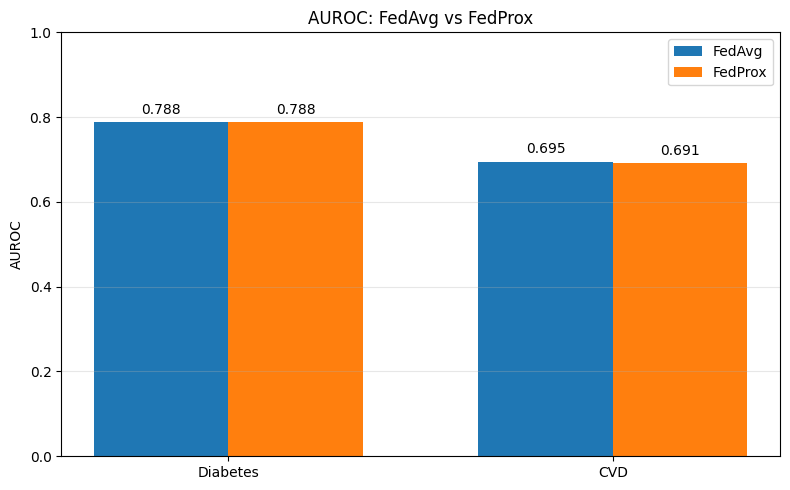

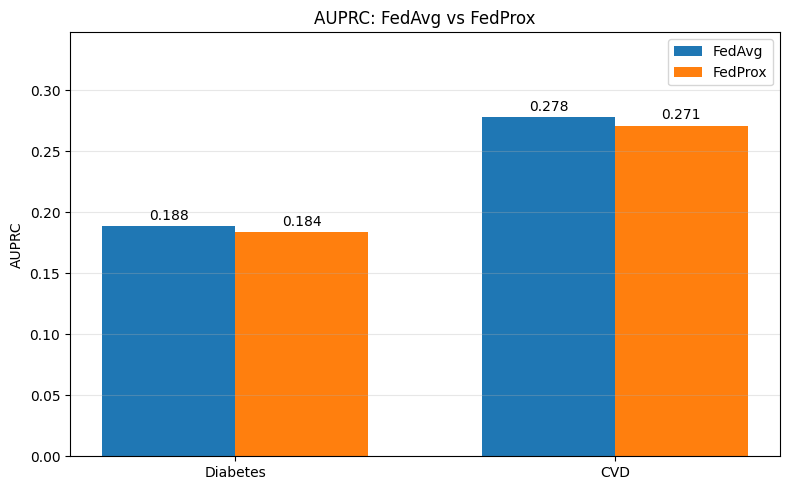

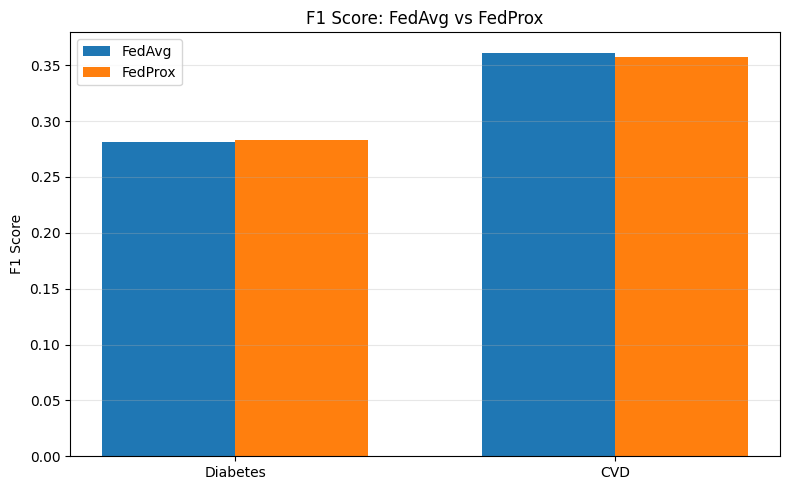

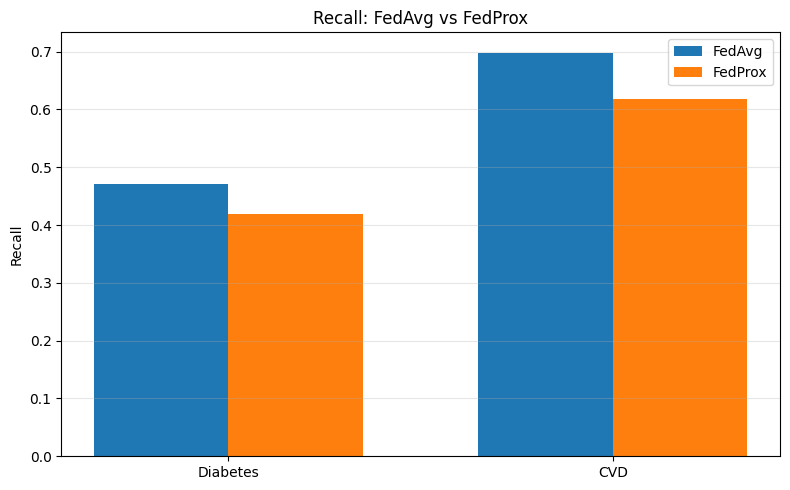

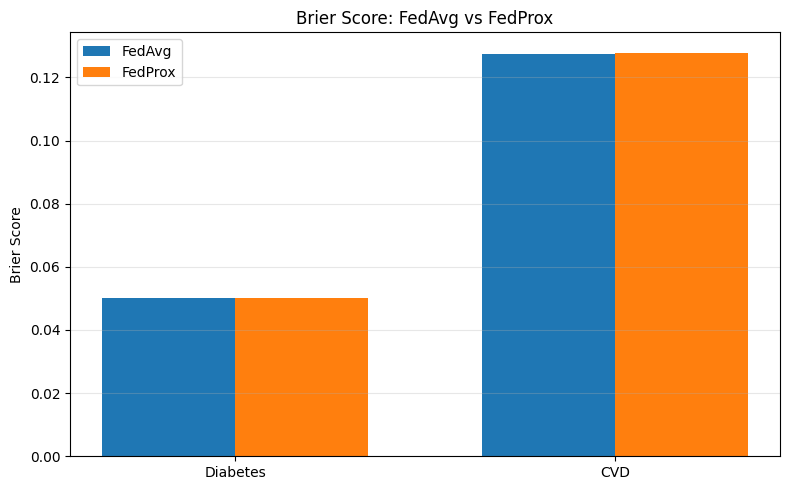

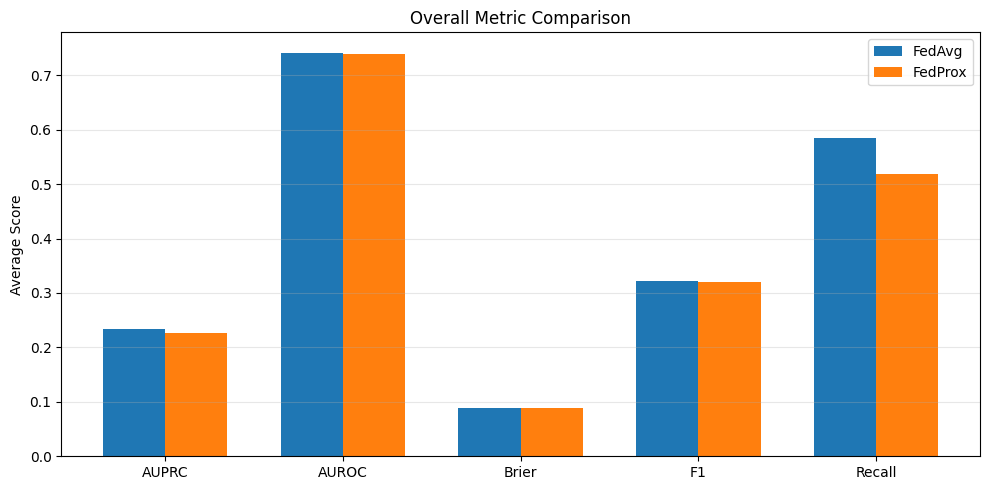


FEDPROX vs FEDAVG DIFFERENCE


,Disease,Metric,FedAvg,FedProx,Difference,Change (%)
0,Diabetes,AUROC,0.7882,0.7885,+0.0003,+0.03%
1,Diabetes,AUPRC,0.1883,0.1837,-0.0046,-2.46%
2,Diabetes,F1,0.2814,0.2835,+0.0021,+0.75%
3,Diabetes,Recall,0.4707,0.4189,-0.0517,-10.99%
4,Diabetes,Brier,0.0502,0.0502,-0.0000,-0.03%
5,CVD,AUROC,0.6953,0.6913,-0.0039,-0.57%
6,CVD,AUPRC,0.2779,0.2709,-0.0069,-2.49%
7,CVD,F1,0.3614,0.3571,-0.0043,-1.18%
8,CVD,Recall,0.6985,0.6188,-0.0797,-11.41%
9,CVD,Brier,0.1274,0.1279,+0.0004,+0.35%



BEST MODEL BY METRIC
Diabetes   | AUROC    | Best: FedProx
Diabetes   | AUPRC    | Best: FedAvg
Diabetes   | F1       | Best: FedProx
Diabetes   | Recall   | Best: FedAvg
Diabetes   | Brier    | Best: FedProx
CVD        | AUROC    | Best: FedAvg
CVD        | AUPRC    | Best: FedAvg
CVD        | F1       | Best: FedAvg
CVD        | Recall   | Best: FedAvg
CVD        | Brier    | Best: FedAvg

FINAL SUMMARY
Average FedAvg score : 0.3939
Average FedProx score: 0.3791


In [115]:
# ============================================================
# FINAL RESULTS: FEDAVG vs FEDPROX
# Comprehensive Metrics + Comparisons + Visualizations
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Collect results from the existing evaluation dictionaries
# ------------------------------------------------------------

metrics = [
    "AUROC",
    "AUPRC",
    "F1",
    "Recall",
    "Brier"
]

metric_keys = {
    "AUROC": "auroc",
    "AUPRC": "auprc",
    "F1": "f1",
    "Recall": "recall",
    "Brier": "brier"
}

# Build a clean results table
comparison_data = []

for disease in ["Diabetes", "CVD"]:

    disease_prefix = disease.lower()

    for metric in metrics:

        key = f"{disease_prefix}_{metric_keys[metric]}"

        comparison_data.append({
            "Disease": disease,
            "Metric": metric,
            "FedAvg": results[key],
            "FedProx": fedprox_results[key]
        })

comparison_df = pd.DataFrame(comparison_data)

# ------------------------------------------------------------
# 2. Display complete numerical comparison
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("FINAL MODEL PERFORMANCE COMPARISON")
print("=" * 75)

display(
    comparison_df.style
    .format({
        "FedAvg": "{:.4f}",
        "FedProx": "{:.4f}"
    })
)

# ------------------------------------------------------------
# 3. Print individual disease summaries
# ------------------------------------------------------------

for disease in ["Diabetes", "CVD"]:

    print("\n" + "-" * 75)
    print(f"{disease.upper()} RESULTS")
    print("-" * 75)

    disease_df = comparison_df[
        comparison_df["Disease"] == disease
    ].copy()

    print(
        disease_df[
            ["Metric", "FedAvg", "FedProx"]
        ].to_string(index=False, float_format=lambda x: f"{x:.4f}")
    )


# ============================================================
# GRAPH 1: AUROC Comparison
# ============================================================

auroc_df = comparison_df[
    comparison_df["Metric"] == "AUROC"
]

x = np.arange(len(auroc_df))
width = 0.35

plt.figure(figsize=(8, 5))

plt.bar(
    x - width / 2,
    auroc_df["FedAvg"],
    width,
    label="FedAvg"
)

plt.bar(
    x + width / 2,
    auroc_df["FedProx"],
    width,
    label="FedProx"
)

plt.xticks(x, auroc_df["Disease"])
plt.ylabel("AUROC")
plt.title("AUROC: FedAvg vs FedProx")
plt.ylim(0, 1)
plt.legend()
plt.grid(axis="y", alpha=0.3)

for i, value in enumerate(auroc_df["FedAvg"]):
    plt.text(
        i - width / 2,
        value + 0.02,
        f"{value:.3f}",
        ha="center"
    )

for i, value in enumerate(auroc_df["FedProx"]):
    plt.text(
        i + width / 2,
        value + 0.02,
        f"{value:.3f}",
        ha="center"
    )

plt.tight_layout()
plt.show()


# ============================================================
# GRAPH 2: AUPRC Comparison
# ============================================================

auprc_df = comparison_df[
    comparison_df["Metric"] == "AUPRC"
]

x = np.arange(len(auprc_df))

plt.figure(figsize=(8, 5))

plt.bar(
    x - width / 2,
    auprc_df["FedAvg"],
    width,
    label="FedAvg"
)

plt.bar(
    x + width / 2,
    auprc_df["FedProx"],
    width,
    label="FedProx"
)

plt.xticks(x, auprc_df["Disease"])
plt.ylabel("AUPRC")
plt.title("AUPRC: FedAvg vs FedProx")
plt.ylim(0, max(
    auprc_df["FedAvg"].max(),
    auprc_df["FedProx"].max()
) * 1.25)

plt.legend()
plt.grid(axis="y", alpha=0.3)

for i, value in enumerate(auprc_df["FedAvg"]):
    plt.text(
        i - width / 2,
        value + 0.005,
        f"{value:.3f}",
        ha="center"
    )

for i, value in enumerate(auprc_df["FedProx"]):
    plt.text(
        i + width / 2,
        value + 0.005,
        f"{value:.3f}",
        ha="center"
    )

plt.tight_layout()
plt.show()


# ============================================================
# GRAPH 3: F1 Score Comparison
# ============================================================

f1_df = comparison_df[
    comparison_df["Metric"] == "F1"
]

x = np.arange(len(f1_df))

plt.figure(figsize=(8, 5))

plt.bar(
    x - width / 2,
    f1_df["FedAvg"],
    width,
    label="FedAvg"
)

plt.bar(
    x + width / 2,
    f1_df["FedProx"],
    width,
    label="FedProx"
)

plt.xticks(x, f1_df["Disease"])
plt.ylabel("F1 Score")
plt.title("F1 Score: FedAvg vs FedProx")
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# GRAPH 4: Recall Comparison
# ============================================================

recall_df = comparison_df[
    comparison_df["Metric"] == "Recall"
]

x = np.arange(len(recall_df))

plt.figure(figsize=(8, 5))

plt.bar(
    x - width / 2,
    recall_df["FedAvg"],
    width,
    label="FedAvg"
)

plt.bar(
    x + width / 2,
    recall_df["FedProx"],
    width,
    label="FedProx"
)

plt.xticks(x, recall_df["Disease"])
plt.ylabel("Recall")
plt.title("Recall: FedAvg vs FedProx")
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# GRAPH 5: Brier Score Comparison
# Lower is better
# ============================================================

brier_df = comparison_df[
    comparison_df["Metric"] == "Brier"
]

x = np.arange(len(brier_df))

plt.figure(figsize=(8, 5))

plt.bar(
    x - width / 2,
    brier_df["FedAvg"],
    width,
    label="FedAvg"
)

plt.bar(
    x + width / 2,
    brier_df["FedProx"],
    width,
    label="FedProx"
)

plt.xticks(x, brier_df["Disease"])
plt.ylabel("Brier Score")
plt.title("Brier Score: FedAvg vs FedProx")
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# GRAPH 6: Overall Metric Comparison
# ============================================================

# Average each metric across Diabetes + CVD
overall_df = comparison_df.groupby("Metric")[
    ["FedAvg", "FedProx"]
].mean()

x = np.arange(len(overall_df))

plt.figure(figsize=(10, 5))

plt.bar(
    x - width / 2,
    overall_df["FedAvg"],
    width,
    label="FedAvg"
)

plt.bar(
    x + width / 2,
    overall_df["FedProx"],
    width,
    label="FedProx"
)

plt.xticks(x, overall_df.index)
plt.ylabel("Average Score")
plt.title("Overall Metric Comparison")
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# 4. Percentage improvement / difference
# ============================================================

difference_rows = []

for _, row in comparison_df.iterrows():

    fedavg = row["FedAvg"]
    fedprox = row["FedProx"]

    difference = fedprox - fedavg

    if fedavg != 0:
        percentage_change = (difference / abs(fedavg)) * 100
    else:
        percentage_change = np.nan

    difference_rows.append({
        "Disease": row["Disease"],
        "Metric": row["Metric"],
        "FedAvg": fedavg,
        "FedProx": fedprox,
        "Difference": difference,
        "Change (%)": percentage_change
    })

difference_df = pd.DataFrame(difference_rows)

print("\n" + "=" * 75)
print("FEDPROX vs FEDAVG DIFFERENCE")
print("=" * 75)

display(
    difference_df.style.format({
        "FedAvg": "{:.4f}",
        "FedProx": "{:.4f}",
        "Difference": "{:+.4f}",
        "Change (%)": "{:+.2f}%"
    })
)


# ============================================================
# 5. Automatically identify the better model
# ============================================================

print("\n" + "=" * 75)
print("BEST MODEL BY METRIC")
print("=" * 75)

for _, row in comparison_df.iterrows():

    # Higher is better for these
    if row["Metric"] in ["AUROC", "AUPRC", "F1", "Recall"]:

        if row["FedAvg"] > row["FedProx"]:
            winner = "FedAvg"
        elif row["FedProx"] > row["FedAvg"]:
            winner = "FedProx"
        else:
            winner = "Tie"

    # Lower is better for Brier score
    else:

        if row["FedAvg"] < row["FedProx"]:
            winner = "FedAvg"
        elif row["FedProx"] < row["FedAvg"]:
            winner = "FedProx"
        else:
            winner = "Tie"

    print(
        f"{row['Disease']:10s} | "
        f"{row['Metric']:8s} | "
        f"Best: {winner}"
    )


# ============================================================
# 6. Final summary
# ============================================================

print("\n" + "=" * 75)
print("FINAL SUMMARY")
print("=" * 75)

avg_fedavg = overall_df["FedAvg"].mean()
avg_fedprox = overall_df["FedProx"].mean()

print(f"Average FedAvg score : {avg_fedavg:.4f}")
print(f"Average FedProx score: {avg_fedprox:.4f}")

## Diagnostics

In [103]:

import numpy as np
from sklearn.metrics import confusion_matrix, classification_report

def diagnose_predictions(y_true, y_prob, threshold=0.5, task_name="Task"):
    y_true = np.asarray(y_true).astype(int).ravel()
    y_prob = np.asarray(y_prob).ravel()

    y_pred = (y_prob >= threshold).astype(int)

    print(f"\n{'=' * 45}")
    print(f"Diagnostics: {task_name}")
    print(f"{'=' * 45}")

    print("Number of samples:", len(y_true))
    print("Positive cases:", np.sum(y_true == 1))
    print("Negative cases:", np.sum(y_true == 0))
    print("Positive prevalence:", round(np.mean(y_true), 4))

    print("\nPredicted probability distribution:")
    for label, mask in [
        ("Actual positives", y_true == 1),
        ("Actual negatives", y_true == 0),
    ]:
        probs = y_prob[mask]
        if len(probs):
            print(
                f"{label}:",
                "mean =", round(float(np.mean(probs)), 4),
                "median =", round(float(np.median(probs)), 4),
                "min =", round(float(np.min(probs)), 4),
                "max =", round(float(np.max(probs)), 4),
                ">= threshold =", int(np.sum(probs >= threshold))
            )

    print("\nConfusion matrix [[TN, FP], [FN, TP]]:")
    print(confusion_matrix(y_true, y_pred, labels=[0, 1]))

    print("\nClassification report:")
    print(classification_report(
        y_true, y_pred, labels=[0, 1],
        target_names=["Negative", "Positive"],
        zero_division=0
    ))


In [104]:
import torch
import numpy as np

def get_predictions_and_targets(model, dataloader):
    model.eval()
    diabetes_probs = []
    diabetes_true = []
    cvd_probs = []
    cvd_true = []

    with torch.no_grad():
        for x, y_diabetes, y_cvd in dataloader:
            x = x.to(device)
            diabetes_logits, cvd_logits = model(x)

            diabetes_predictions = torch.sigmoid(diabetes_logits).cpu().numpy().flatten()
            cvd_predictions = torch.sigmoid(cvd_logits).cpu().numpy().flatten()

            y_diabetes = y_diabetes.numpy()
            y_cvd = y_cvd.numpy()

            diabetes_mask = ~np.isnan(y_diabetes)
            diabetes_probs.extend(diabetes_predictions[diabetes_mask])
            diabetes_true.extend(y_diabetes[diabetes_mask])

            cvd_mask = ~np.isnan(y_cvd)
            cvd_probs.extend(cvd_predictions[cvd_mask])
            cvd_true.extend(y_cvd[cvd_mask])

    return np.array(diabetes_true), np.array(diabetes_probs), np.array(cvd_true), np.array(cvd_probs)

# Get predictions for FedAvg (global_model)
y_test_diabetes, diabetes_probs_fedavg, y_test_cvd, cvd_probs_fedavg = get_predictions_and_targets(global_model, test_loader)

# Get predictions for FedProx (fedprox_model)
_, diabetes_probs_fedprox, _, cvd_probs_fedprox = get_predictions_and_targets(fedprox_model, test_loader)

# Run diagnostics using optimal threshold (0.45 as used in evaluation)
diagnose_predictions(y_test_diabetes, diabetes_probs_fedavg, threshold=0.45, task_name="Diabetes — FedAvg")
diagnose_predictions(y_test_cvd, cvd_probs_fedavg, threshold=0.45, task_name="CVD — FedAvg")
diagnose_predictions(y_test_diabetes, diabetes_probs_fedprox, threshold=0.45, task_name="Diabetes — FedProx")
diagnose_predictions(y_test_cvd, cvd_probs_fedprox, threshold=0.45, task_name="CVD — FedProx")


Diagnostics: Diabetes — FedAvg
Number of samples: 27559
Positive cases: 1585
Negative cases: 25974
Positive prevalence: 0.0575

Predicted probability distribution:
Actual positives: mean = 0.1515 median = 0.1425 min = 0.0018 max = 0.5393 >= threshold = 1
Actual negatives: mean = 0.0668 median = 0.0457 min = 0.0 max = 0.4376 >= threshold = 0

Confusion matrix [[TN, FP], [FN, TP]]:
[[25974     0]
 [ 1584     1]]

Classification report:
              precision    recall  f1-score   support

    Negative       0.94      1.00      0.97     25974
    Positive       1.00      0.00      0.00      1585

    accuracy                           0.94     27559
   macro avg       0.97      0.50      0.49     27559
weighted avg       0.95      0.94      0.91     27559


Diagnostics: CVD — FedAvg
Number of samples: 27559
Positive cases: 4468
Negative cases: 23091
Positive prevalence: 0.1621

Predicted probability distribution:
Actual positives: mean = 0.2289 median = 0.2332 min = 0.0186 max = 0.654 >

## Save the models and Config

In [117]:
from pathlib import Path
import torch
import json

# Create a folder for the dashboard's trained models
MODEL_DIR = Path("saved_models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Save trained model weights
torch.save(
    global_model.state_dict(),
    MODEL_DIR / "fedavg_model.pth"
)

torch.save(
    fedprox_model.state_dict(),
    MODEL_DIR / "fedprox_model.pth"
)

print("Both trained models saved successfully!")
print(list(MODEL_DIR.iterdir()))

Both trained models saved successfully!
[PosixPath('saved_models/fedprox_model.pth'), PosixPath('saved_models/fedavg_model.pth')]


In [118]:
# Save the model configuration

config = {
    "input_features": 12,
    "hidden_layers": [64, 32],
    "dropout": 0.2,
    "tasks": ["diabetes", "cvd"],
    "models": ["fedavg", "fedprox"]
}

with open(MODEL_DIR / "model_config.json", "w") as f:
    json.dump(config, f, indent=4)

print("Model configuration saved!")

Model configuration saved!


In [119]:
# Save your feature names and preprocessing

feature_info = {
    "feature_names": list(X_train.columns),
    "feature_count": len(X_train.columns)
}

with open(MODEL_DIR / "feature_info.json", "w") as f:
    json.dump(feature_info, f, indent=4)

print("Feature information saved!")
print(feature_info["feature_names"])

Feature information saved!
['anchor_age', 'gender', 'bmi', 'systolic_bp', 'diastolic_bp', 'glucose', 'hba1c', 'ldl', 'hdl', 'triglycerides', 'creatinine', 'potassium']


In [120]:
# Save the thresholds

thresholds = {
    "original": {
        "diabetes": 0.15,
        "cvd": 0.20
    },
    "fedavg_validation_tuned": {
        "diabetes": 0.15,
        "cvd": 0.20
    },
    "fedprox_validation_tuned": {
        "diabetes": 0.15,
        "cvd": 0.20
    }
}

with open(MODEL_DIR / "thresholds.json", "w") as f:
    json.dump(thresholds, f, indent=4)

print("Thresholds saved!")

Thresholds saved!


## Save to the drive

In [122]:
from pathlib import Path

MODEL_DIR = Path(
    "/content/drive/MyDrive/FederatedRiskProject/saved_models"
)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Save trained models
torch.save(
    global_model.state_dict(),
    MODEL_DIR / "fedavg_model.pth"
)

torch.save(
    fedprox_model.state_dict(),
    MODEL_DIR / "fedprox_model.pth"
)

# Save configuration, feature metadata, and thresholds
with open(MODEL_DIR / "model_config.json", "w") as f:
    json.dump(config, f, indent=4)

with open(MODEL_DIR / "feature_info.json", "w") as f:
    json.dump(feature_info, f, indent=4)

with open(MODEL_DIR / "thresholds.json", "w") as f:
    json.dump(thresholds, f, indent=4)

print("Saved permanently to Google Drive:")
for file in MODEL_DIR.iterdir():
    print(file.name)

Saved permanently to Google Drive:
fedavg_model.pth
fedprox_model.pth
model_config.json
feature_info.json
thresholds.json
